# Portuguese Bank Marketing — PRCP-1000

## 1. Project Overview

### Business Problem
The bank wants to improve the effectiveness of its direct telephone marketing campaigns by identifying customers who are more likely to subscribe to a term deposit.

### Project Objectives
- Perform exploratory data analysis on the bank marketing dataset.
- Clean and preprocess the data.
- Identify patterns in customer characteristics and campaign outcomes.
- Build and compare machine learning classification models.
- Evaluate model performance using appropriate metrics.
- Develop business recommendations based on the findings.

### Target Variable
The target variable is `y`, which indicates whether a customer subscribed to a term deposit (`yes` or `no`).

### Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Jupyter Notebook.

In [1]:
import sys
print(sys.executable)

import pandas as pd
print("Pandas version:", pd.__version__)
print("Pandas is working!")

c:\Users\yaswi\.ms-ad\python.exe
Pandas version: 2.3.3
Pandas is working!


## 2. Dataset Loading and Initial Inspection

### Objective
Load the Portuguese Bank Marketing dataset into a Pandas DataFrame and inspect its structure.

### Why are we doing this?
Before analysing the data, we need to understand its size, column names, and sample records. This helps us verify that the correct dataset has been loaded.

### Dataset
We are using `bank-additional-full.csv`, as specified in the PRCP-1000 project instructions.

### Expected outcome
- Load the dataset successfully.
- Display the first five records.
- Check the number of rows and columns.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [1]:
from pathlib import Path

# Check the current working directory
print("Current folder:", Path.cwd())

# Check the expected dataset location
file_path = Path("bank-additional-full.csv")
print("File exists:", file_path.exists())
print("Expected path:", file_path.resolve())

Current folder: c:\Users\yaswi\Datamites Capston Projects\Portuguese Bank Marketing
File exists: True
Expected path: C:\Users\yaswi\Datamites Capston Projects\Portuguese Bank Marketing\bank-additional-full.csv


In [4]:
# Load the Portuguese Bank Marketing dataset
df = pd.read_csv(
    "Data/bank-additional/bank-additional-full.csv",
    sep=";"
)

# Display the first five rows
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Initial Dataset Inspection

### Objective
Understand the size, structure, column names, and data types of the dataset before performing data cleaning.

### Explanation
The dataset contains customer information, campaign details, economic indicators, and the target variable `y`. The `df.head()` command displays the first five records as a preview.

### Next steps
- Check the total number of records and columns.
- Inspect the data types.
- Identify missing values and duplicates.
- Understand the distribution of the target variable.

In [5]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names, data types and non-null counts
df.info()

Dataset shape: (41188, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons

## 4. Data Quality Assessment: Missing Values and Duplicates

### Objective
Check the dataset for missing values and duplicate records before making any changes.

### Why is this important?
Missing values can affect analysis and model training. Duplicate records may cause some observations to be counted more than once.

The dataset also contains categorical values such as `unknown`. These are not necessarily standard missing values, so they must be examined separately.

### Approach
- Count missing values in each column.
- Count duplicate rows.
- Inspect the frequency of `unknown` values in categorical columns.

We will review the results before deciding whether any cleaning is necessary.

In [6]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Missing values by column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Total missing values: 0
Total duplicate rows: 12


In [7]:
# Identify categorical columns
categorical_columns = df.select_dtypes(
    include="object"
).columns

# Count unknown values in each categorical column
for column in categorical_columns:
    unknown_count = (
        df[column].astype(str).str.lower() == "unknown"
    ).sum()

    if unknown_count > 0:
        print(f"{column}: {unknown_count} unknown values")

job: 330 unknown values
marital: 80 unknown values
education: 1731 unknown values
default: 8597 unknown values
housing: 990 unknown values
loan: 990 unknown values


### Observations from the Data Quality Check

After checking the dataset, I found that some categorical columns contain values marked as `unknown`. The `default` column has the highest number of unknown values, followed by `education`.

| Column | Unknown values |
|---|---:|
| default | 8,597 |
| education | 1,731 |
| housing | 990 |
| loan | 990 |
| job | 330 |
| marital | 80 |

These values indicate that some customer details are not available in the dataset. Instead of immediately deleting these records or replacing the values, I will examine their distribution and decide how to handle them during preprocessing.

In [8]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("\nTotal duplicate rows:", duplicate_count)

Missing values by column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Total missing values: 0

Total duplicate rows: 12


### Understanding Missing Values and Duplicate Records

At this stage, I am checking whether the dataset contains any standard missing values or duplicate records. This helps me understand whether the data needs any cleaning before moving to exploratory data analysis.

I will use the results to decide whether any changes are necessary. I will avoid removing records unless there is a clear reason to do so.

### Findings from the Data Quality Assessment

After checking the dataset, I found that there are no standard missing values in any of the 21 columns. However, some categorical columns contain values marked as `unknown`, which I will consider during preprocessing.

The dataset also contains 12 duplicate rows. Before removing them, I will check these records to understand whether they are exact duplicates.

Overall, the dataset is in good shape for further analysis, but the duplicate records and unknown categorical values need to be considered before building the model.

In [9]:
# Display duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

print("Number of rows involved in duplicates:", len(duplicate_rows))

duplicate_rows.head(20)

Number of rows involved in duplicates: 24


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


In [10]:
# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (41176, 21)
Remaining duplicate rows: 0


### Handling Duplicate Records

After inspecting the duplicate records, I found that some rows contained exactly the same information across all columns. I removed the extra copies and kept one instance of each record.

This helps prevent identical records from being counted more than once during the analysis. The dataset is now ready for exploratory data analysis, while the `unknown` values will be handled carefully during preprocessing.

## 5. Exploratory Data Analysis

Before building a machine learning model, I want to understand the dataset and identify patterns in customer behaviour. This will help me explore which customer characteristics and campaign-related factors are associated with term-deposit subscriptions.

I will begin by examining the target column, `y`, to understand how many customers subscribed and how many did not. This will also help me check whether the dataset is balanced or whether one outcome is much more common than the other.

In [11]:
# Count customers in each target category
target_counts = df["y"].value_counts()

print("Term deposit subscription counts:")
print(target_counts)

print("\nSubscription percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

Term deposit subscription counts:
y
no     36537
yes     4639
Name: count, dtype: int64

Subscription percentages:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


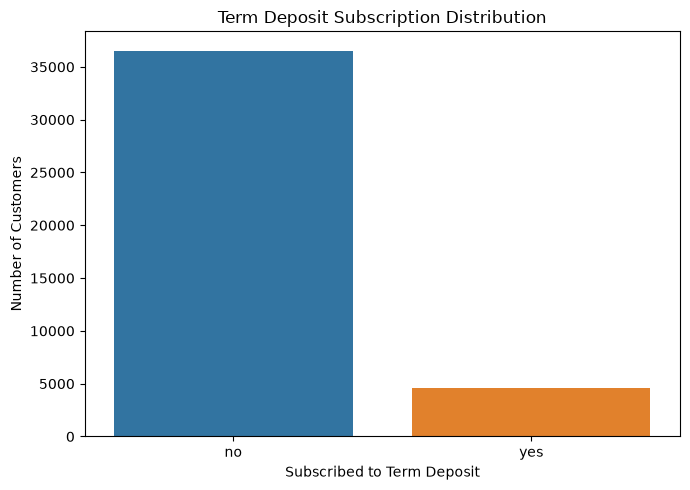

In [12]:
# Visualize term deposit subscription outcomes
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y", hue="y", legend=False)

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Analysis of Term Deposit Subscription

The chart shows that most customers contacted during the marketing campaigns did not subscribe to the term deposit.

Out of 41,176 records, 36,537 customers (88.73%) did not subscribe, while 4,639 customers (11.27%) subscribed. This shows that the dataset has an imbalance between the two target categories.

This finding is important for the next stages of the project. A machine learning model could predict that most customers will not subscribe and still achieve a seemingly high accuracy. Therefore, I will also consider metrics such as precision, recall, F1-score and ROC-AUC when evaluating the models.

### Customer Age Analysis

I will now examine the age distribution of customers in the dataset. Understanding the age groups can help me identify the customer segments represented in the campaign.

I will first look at the overall age distribution and then compare the ages of customers who subscribed with those who did not. This will help me explore whether subscription behaviour differs across customer ages.

In [13]:
# Summary of customer ages
print("Customer age summary:")
print(df["age"].describe())

Customer age summary:
count    41176.00000
mean        40.02380
std         10.42068
min         17.00000
25%         32.00000
50%         38.00000
75%         47.00000
max         98.00000
Name: age, dtype: float64


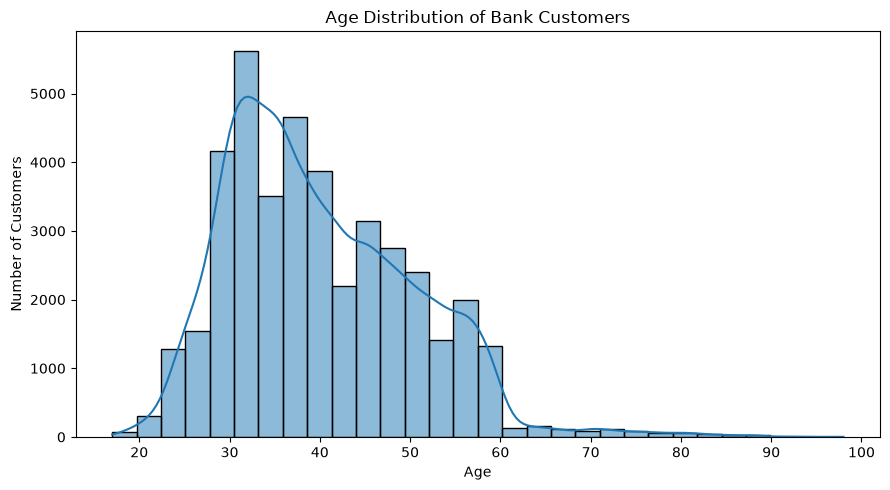

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Age Distribution of Bank Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

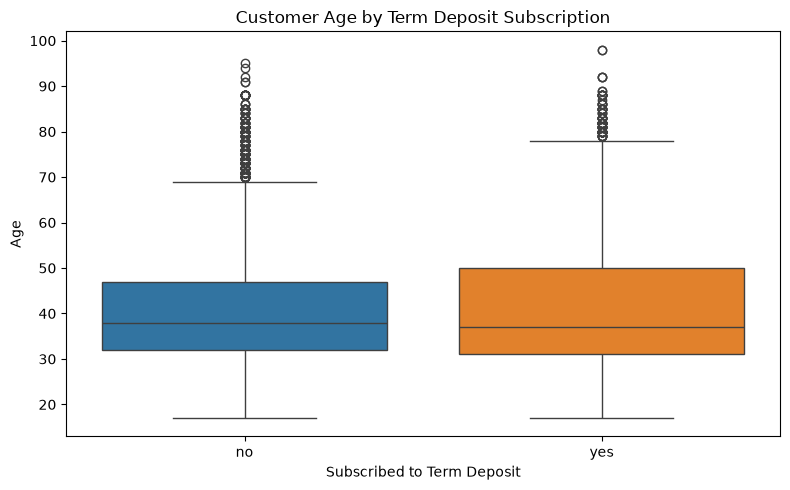

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="y", y="age", hue="y", legend=False)

plt.title("Customer Age by Term Deposit Subscription")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

### Findings from Customer Age Analysis

The age analysis shows that customers in this dataset range from 17 to 98 years old. The average age is approximately 40 years, while the median age is 38 years. Most customers are concentrated between their early 30s and late 40s.

The box plot shows that the age distributions of customers who subscribed and those who did not are quite similar. The median age of customers who subscribed appears slightly lower than that of customers who did not subscribe. However, the plot alone does not establish whether age has a strong relationship with subscription behaviour.

These findings suggest that the campaign reached customers from different age groups. I will explore other customer characteristics and campaign-related factors before deciding which features may be useful for predicting subscriptions.

### Customer Job and Subscription Analysis

I will now explore the job categories recorded in the dataset. This will help me understand the employment backgrounds of the customers contacted during the campaign.

I will first compare the number of customers in each job category. Then, I will examine the subscription rate within each category to see whether the proportion of customers who subscribed varies by occupation.

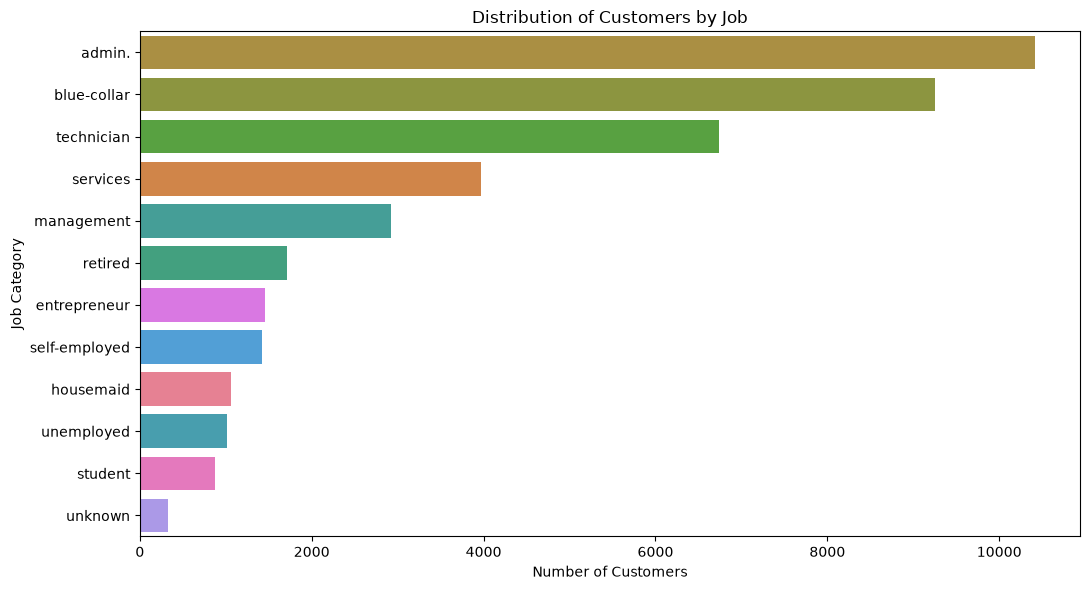

In [16]:
# Count customers in each job category
job_counts = df["job"].value_counts()

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y="job",
    order=job_counts.index,
    hue="job",
    legend=False
)

plt.title("Distribution of Customers by Job")
plt.xlabel("Number of Customers")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()


Subscription rate by job (%):
job
student          31.43
retired          25.26
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.90
Name: y, dtype: float64


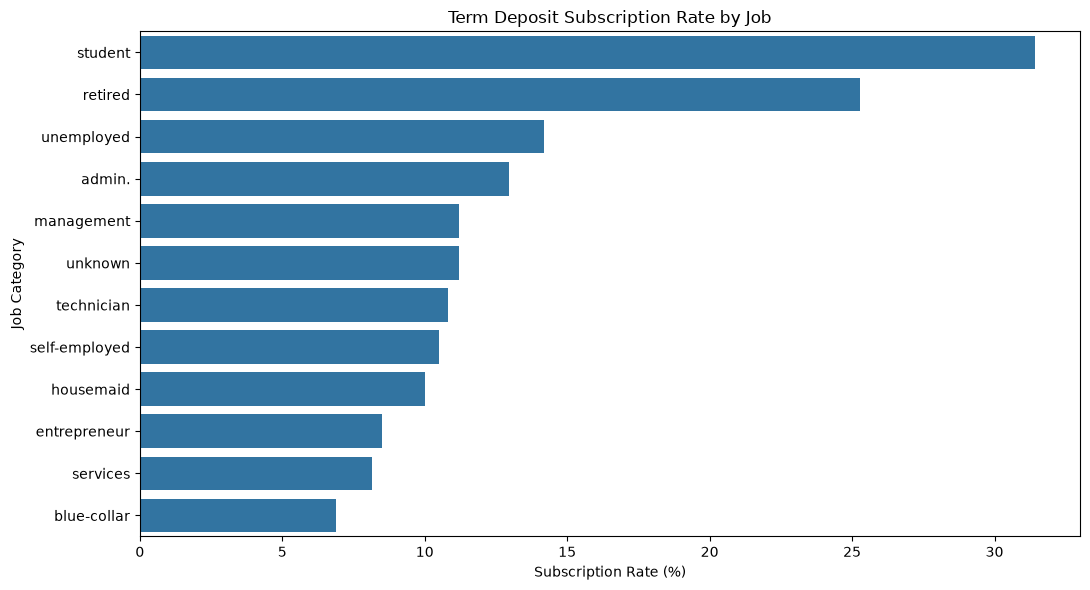

In [17]:
# Calculate subscription rate for each job category
job_subscription = (
    df.groupby("job", observed=False)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Subscription rate by job (%):")
print(job_subscription.round(2))

plt.figure(figsize=(11, 6))

sns.barplot(
    x=job_subscription.values,
    y=job_subscription.index
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

### Findings from Customer Job Analysis

The job distribution chart shows that administrative staff (`admin.`), blue-collar workers and technicians make up a large part of the customers contacted during the campaign.

When I compared subscription rates across job categories, I found that students had the highest rate at 31.43%, followed by retired customers at 25.26%. Unemployed customers had a subscription rate of 14.20%.

On the other hand, blue-collar workers had a subscription rate of 6.90%, while customers working in services and entrepreneurs had rates of 8.14% and 8.52%, respectively.

These results suggest that subscription behaviour varies across job categories. However, a higher rate does not necessarily mean that a category contributes the largest number of subscriptions, because the number of customers in each category also matters. I will consider both customer counts and subscription rates when developing marketing recommendations.

### Marital Status and Subscription Analysis

I will now examine the marital status of customers contacted during the campaign. This analysis will help me understand how customers are distributed across the recorded marital-status categories and whether their subscription rates differ.

I will compare both the number of customers and the subscription rate for each category so that I can interpret the results more accurately.

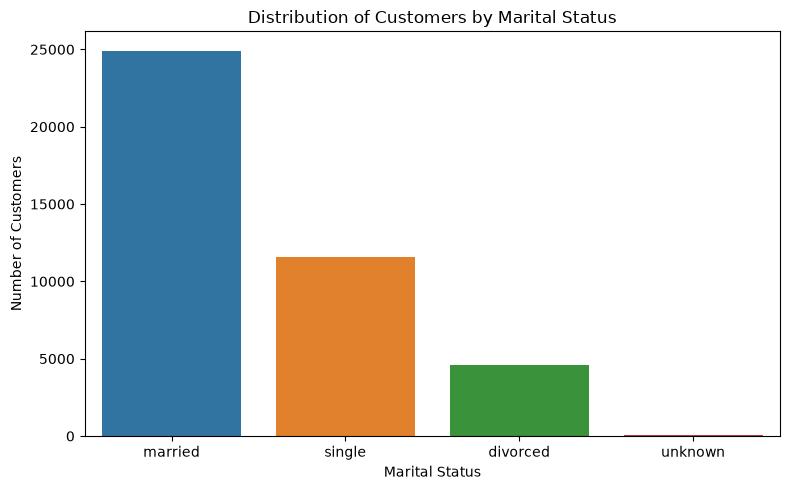

In [18]:
# Count customers by marital status
marital_counts = df["marital"].value_counts()

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="marital",
    order=marital_counts.index,
    hue="marital",
    legend=False
)

plt.title("Distribution of Customers by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Subscription rate by marital status (%):
marital
unknown     15.00
single      14.01
divorced    10.32
married     10.16
Name: y, dtype: float64


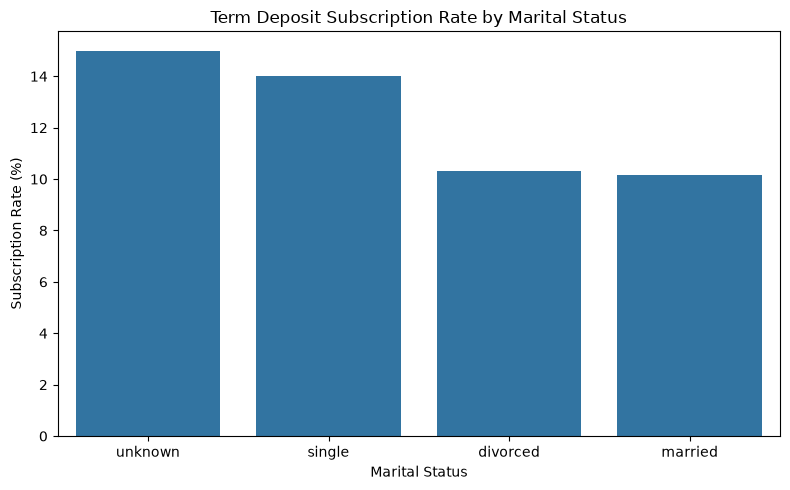

In [19]:
# Calculate subscription rate by marital status
marital_subscription = (
    df.groupby("marital")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Subscription rate by marital status (%):")
print(marital_subscription.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=marital_subscription.index,
    y=marital_subscription.values
)

plt.title("Term Deposit Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

### Findings from Marital Status Analysis

The distribution chart shows that married customers make up the largest group in the dataset, followed by single and divorced customers.

When I compared subscription rates, customers with an unknown marital status had the highest rate at 15.00%, followed by single customers at 14.01%. Divorced customers had a rate of 10.32%, while married customers had a rate of 10.16%.

Although married customers represent the largest group, their subscription rate is lower than that of single customers. This shows why it is useful to compare subscription percentages rather than looking only at the number of customers in each category.

These results show differences in subscription rates across marital-status categories, but they do not establish that marital status alone determines whether a customer will subscribe.

### Customer Education and Subscription Analysis

I will now examine the education levels recorded in the dataset. This will help me understand the educational backgrounds of the customers contacted during the campaign.

I will compare the number of customers in each education category and calculate the subscription rate for each group. This will help me identify differences in subscription behaviour across education levels.

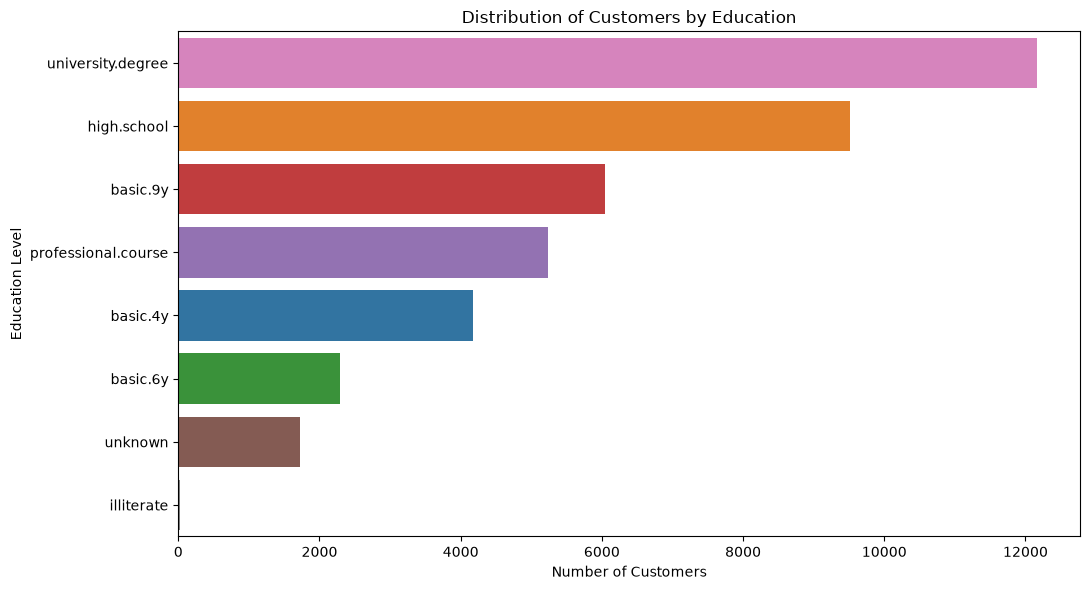

In [20]:
# Count customers by education level
education_counts = df["education"].value_counts()

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y="education",
    order=education_counts.index,
    hue="education",
    legend=False
)

plt.title("Distribution of Customers by Education")
plt.xlabel("Number of Customers")
plt.ylabel("Education Level")
plt.tight_layout()
plt.show()

Subscription rate by education (%):
education
illiterate             22.22
unknown                14.51
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.21
basic.9y                7.82
Name: y, dtype: float64


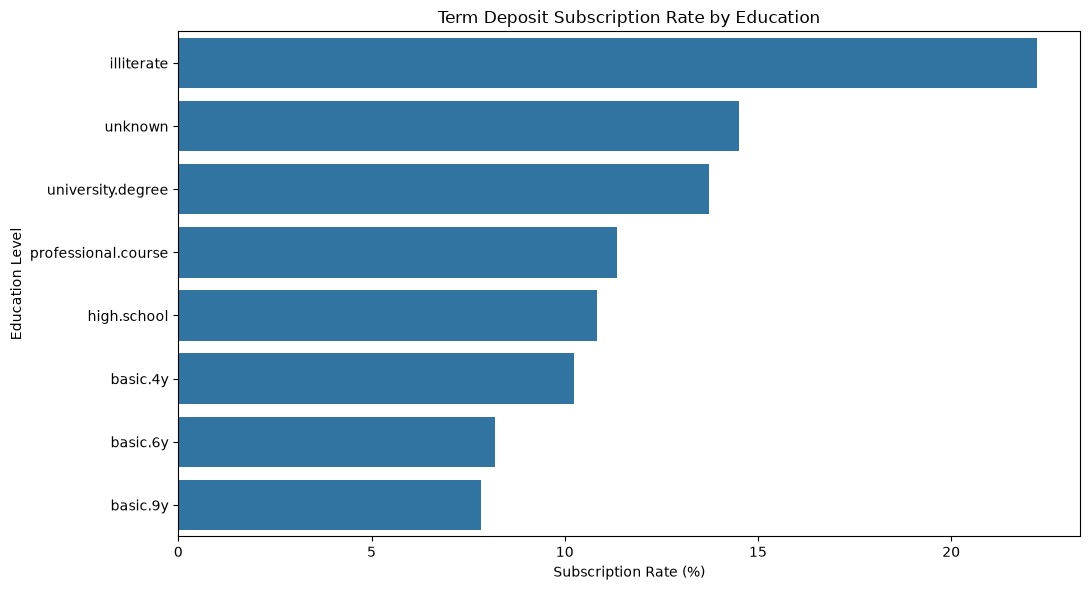

In [21]:
# Calculate subscription rate by education level
education_subscription = (
    df.groupby("education")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Subscription rate by education (%):")
print(education_subscription.round(2))

plt.figure(figsize=(11, 6))

sns.barplot(
    x=education_subscription.values,
    y=education_subscription.index
)

plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Education Level")
plt.tight_layout()
plt.show()

### Findings from Customer Education Analysis

The distribution chart shows that customers with a university degree form the largest education group, followed by customers who completed high school. Customers with basic education also make up a considerable part of the dataset.

When I compared subscription rates, the illiterate category had the highest rate at 22.22%, followed by customers with an unknown education level at 14.51% and those with a university degree at 13.72%. Customers with basic 9th-year education had the lowest rate at 7.82%.

The illiterate category contains very few customers compared with the larger education groups, so its high percentage should be interpreted cautiously. These results show differences in subscription rates across education categories, but further analysis is needed to understand whether education is useful for predicting subscriptions.

### Previous Campaign Outcome Analysis

I will now examine the outcome of previous marketing campaigns. This can help me understand whether customers who responded positively to an earlier campaign also show different subscription behaviour in the current campaign.

I will compare the number of customers in each previous-outcome category and calculate the current subscription rate for each group. This will help me explore whether previous campaign results provide useful information for customer targeting.

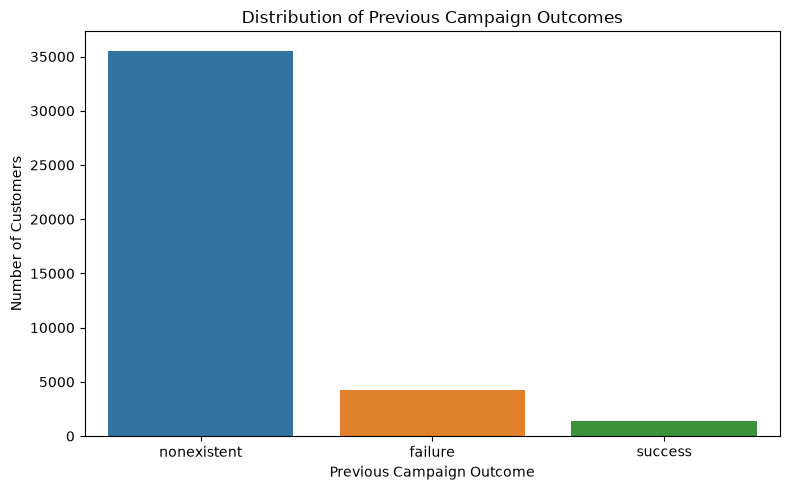

In [22]:
# Count customers by previous campaign outcome
poutcome_counts = df["poutcome"].value_counts()

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="poutcome",
    order=poutcome_counts.index,
    hue="poutcome",
    legend=False
)

plt.title("Distribution of Previous Campaign Outcomes")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Current subscription rate by previous campaign outcome (%):
poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: y, dtype: float64


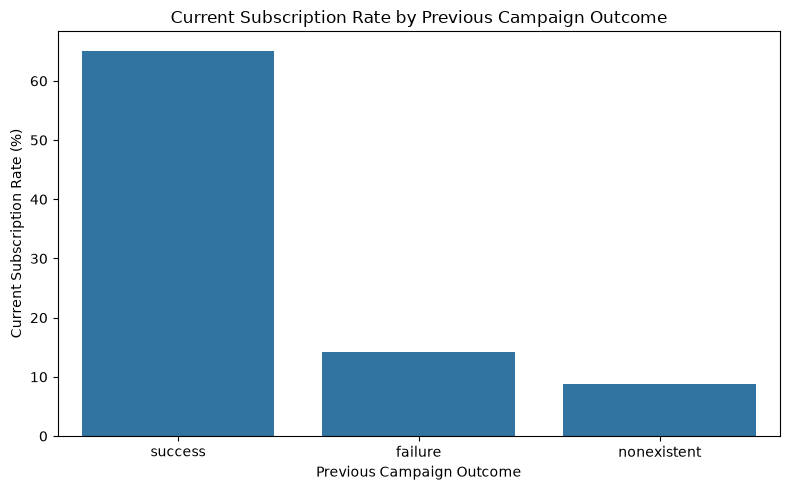

In [23]:
# Calculate current subscription rate by previous campaign outcome
poutcome_subscription = (
    df.groupby("poutcome")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Current subscription rate by previous campaign outcome (%):")
print(poutcome_subscription.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=poutcome_subscription.index,
    y=poutcome_subscription.values
)

plt.title("Current Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Current Subscription Rate (%)")
plt.tight_layout()
plt.show()

### Findings from Previous Campaign Outcome Analysis

The distribution chart shows that most customers had no previous campaign outcome recorded. A smaller number of customers had experienced a previous campaign failure or success.

When I compared current subscription rates, customers whose previous campaign was successful had the highest rate at 65.11%. Customers whose previous campaign had failed had a rate of 14.23%, while customers with no previous campaign outcome recorded had a rate of 8.83%.

This suggests that previous campaign outcomes may provide useful information when identifying customers who are more likely to subscribe. The results could help the marketing team prioritise customers who responded positively in the past.

However, these rates show an association rather than proof that previous campaign success causes a customer to subscribe again. I will also consider which information would be available when making predictions in a real campaign.

### Contact Method and Subscription Analysis

I will now examine how customers were contacted during the marketing campaign. The dataset records whether the contact method was cellular or telephone.

I will compare the number of customers contacted through each method and calculate the subscription rate for each group. This will help me explore whether the observed subscription rates differ between the two contact methods.

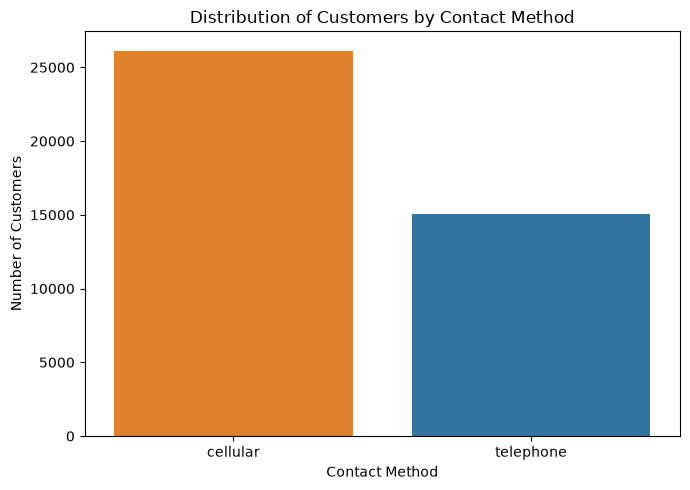

In [24]:
# Count customers by contact method
contact_counts = df["contact"].value_counts()

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="contact",
    order=contact_counts.index,
    hue="contact",
    legend=False
)

plt.title("Distribution of Customers by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Subscription rate by contact method (%):
contact
cellular     14.74
telephone     5.23
Name: y, dtype: float64


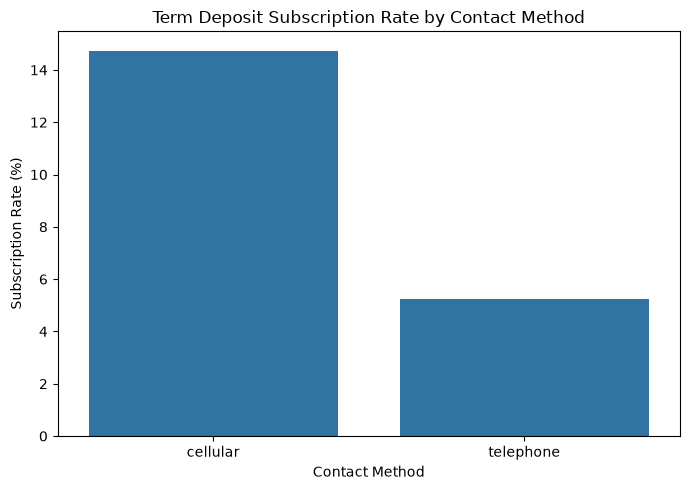

In [25]:
# Calculate subscription rate by contact method
contact_subscription = (
    df.groupby("contact")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Subscription rate by contact method (%):")
print(contact_subscription.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    x=contact_subscription.index,
    y=contact_subscription.values
)

plt.title("Term Deposit Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

### Findings from Contact Method Analysis

The distribution chart shows that cellular was the more frequently used contact method in this dataset. More customers were contacted through cellular than through telephone.

When I compared subscription rates, customers contacted through cellular had a rate of 14.74%, while those contacted through telephone had a rate of 5.23%.

This difference suggests that contact method may be associated with subscription behaviour. The marketing team could investigate whether cellular campaigns are more effective, while also considering other factors such as campaign timing, customer characteristics and the way calls were conducted.

These results alone do not prove that changing the contact method will increase subscriptions, but they provide a useful starting point for further analysis.

### Campaign Month and Subscription Analysis

I will now examine the months in which customers were contacted. Campaign timing may be associated with customer response, so I want to compare both the number of contacts and the subscription rate across months.

This analysis will help me identify months with higher observed subscription rates and provide useful information for planning future marketing campaigns.

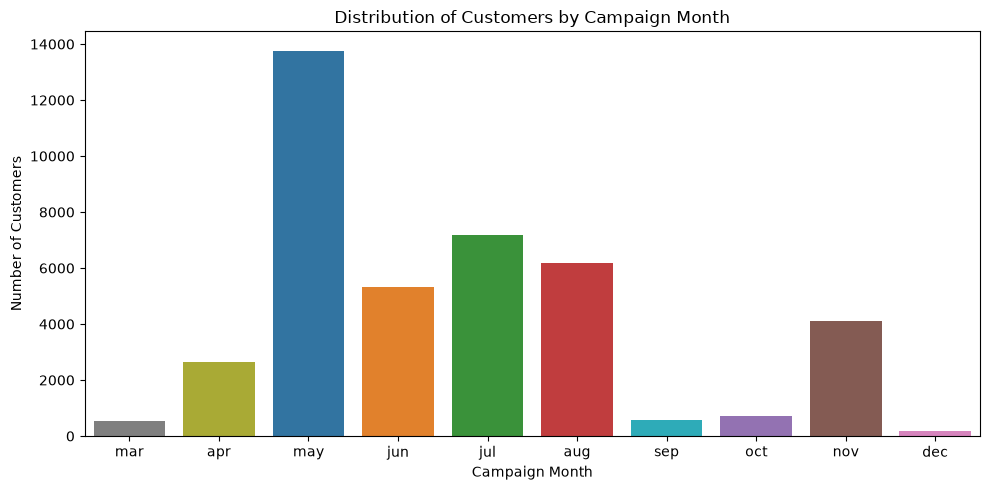

In [26]:
# Order months chronologically
month_order = [
    "mar", "apr", "may", "jun", "jul", "aug",
    "sep", "oct", "nov", "dec"
]

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="month",
    order=month_order,
    hue="month",
    legend=False
)

plt.title("Distribution of Customers by Campaign Month")
plt.xlabel("Campaign Month")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Subscription rate by month (%):
month
mar    50.55
apr    20.49
may     6.44
jun    10.51
jul     9.04
aug    10.61
sep    44.91
oct    43.93
nov    10.15
dec    48.90
Name: y, dtype: float64


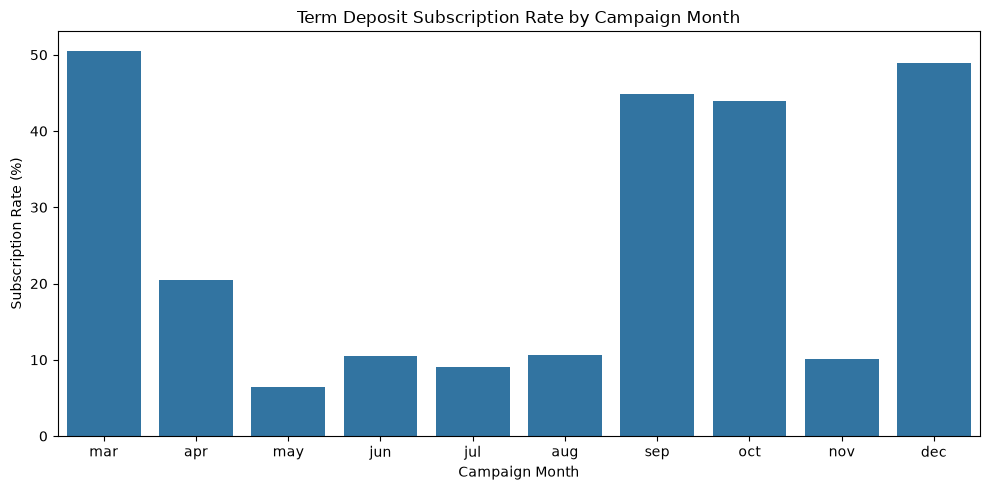

In [27]:
# Calculate subscription rate by campaign month
month_subscription = (
    df.groupby("month")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reindex(month_order)
)

print("Subscription rate by month (%):")
print(month_subscription.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_subscription.index,
    y=month_subscription.values
)

plt.title("Term Deposit Subscription Rate by Campaign Month")
plt.xlabel("Campaign Month")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

### Findings from Campaign Month Analysis

The distribution chart shows that May had the highest number of customer contacts, followed by July and August. In contrast, March, September and December had relatively few contacts.

When I compared subscription rates, March recorded the highest rate at 50.55%, followed by December at 48.90%, September at 44.91% and October at 43.93%. May had the lowest rate at 6.44%.

These results show that the observed subscription rate varied considerably across campaign months. Months with fewer contacts sometimes had much higher subscription rates than months with more contacts.

However, the rates for months with fewer contacts should be interpreted carefully because they are based on smaller groups of customers. The marketing team could investigate whether campaign timing, seasonal factors or other customer characteristics contributed to these differences before deciding when to run future campaigns.

### Day of the Week and Subscription Analysis

I will now examine the days of the week on which customers were contacted. This will help me understand how campaign activity was distributed across weekdays and whether subscription rates differed by day.

I will compare the number of customers contacted on each day with the corresponding subscription rate. These results may help identify patterns worth investigating when planning future campaigns.

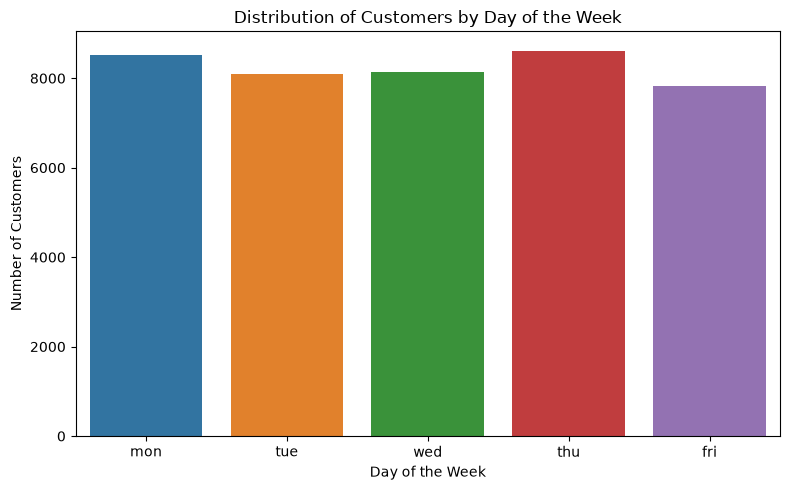

In [28]:
# Arrange days in chronological order
day_order = ["mon", "tue", "wed", "thu", "fri"]

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="day_of_week",
    order=day_order,
    hue="day_of_week",
    legend=False
)

plt.title("Distribution of Customers by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Subscription rate by day of the week (%):
day_of_week
mon     9.95
tue    11.79
wed    11.67
thu    12.11
fri    10.81
Name: y, dtype: float64


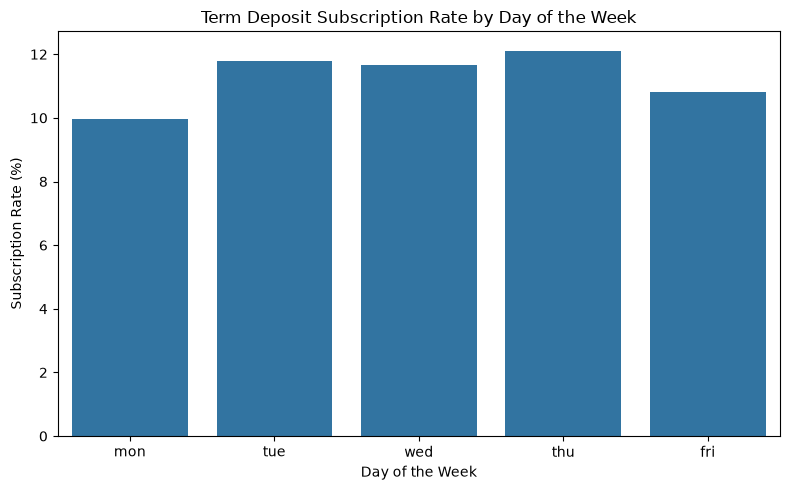

In [29]:
# Calculate subscription rate by day of the week
day_subscription = (
    df.groupby("day_of_week")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reindex(day_order)
)

print("Subscription rate by day of the week (%):")
print(day_subscription.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=day_subscription.index,
    y=day_subscription.values
)

plt.title("Term Deposit Subscription Rate by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

### Findings from Day-of-the-Week Analysis

The distribution chart shows that customer contacts were spread fairly evenly across the five weekdays. Thursday had the highest number of contacts, while Friday had the lowest.

When I compared subscription rates, Thursday recorded the highest rate at 12.11%, followed by Tuesday at 11.79% and Wednesday at 11.67%. Friday had a rate of 10.81%, while Monday recorded the lowest rate at 9.95%.

The differences between weekdays are relatively small compared with the differences observed across campaign months. This suggests that the day of the week may be less informative than some other factors, although its usefulness should ultimately be assessed during model evaluation.

Based on these results, I would not recommend changing the campaign schedule based on weekday alone. The marketing team should consider other factors alongside the day of contact.

### Number of Contacts and Subscription Analysis

I will now examine how many times each customer was contacted during the current marketing campaign. This will help me understand whether subscription rates differ between customers who received fewer contacts and those who received repeated contacts.

I will first review the distribution of contact counts and then compare subscription rates across different contact counts. This may help identify patterns that the marketing team can consider when planning follow-up calls.

In [30]:
# Summary of the number of contacts per customer
print("Campaign contact count summary:")
print(df["campaign"].describe())

print("\nMost common contact counts:")
print(df["campaign"].value_counts().sort_index().head(15))

Campaign contact count summary:
count    41176.000000
mean         2.567879
std          2.770318
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         56.000000
Name: campaign, dtype: float64

Most common contact counts:
campaign
1     17634
2     10568
3      5340
4      2650
5      1599
6       979
7       629
8       400
9       283
10      225
11      177
12      125
13       92
14       69
15       51
Name: count, dtype: int64


Subscription rate by contact count (%):
campaign
1     13.04
2     11.46
3     10.75
4      9.40
5      7.50
6      7.66
7      6.04
8      4.25
9      6.01
10     5.33
11     6.78
12     2.40
Name: y, dtype: float64


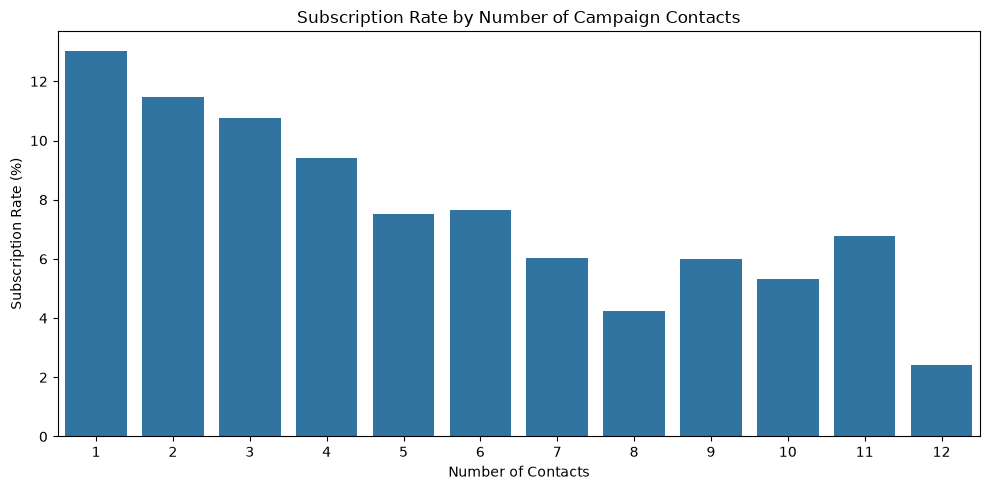

In [31]:
# Calculate subscription rate for each contact count
campaign_subscription = (
    df.groupby("campaign")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

# Display contact counts with at least 100 customers
campaign_sizes = df["campaign"].value_counts()
common_campaign_counts = campaign_sizes[campaign_sizes >= 100].index

campaign_subscription_common = (
    campaign_subscription.loc[common_campaign_counts]
    .sort_index()
)

print("Subscription rate by contact count (%):")
print(campaign_subscription_common.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=campaign_subscription_common.index,
    y=campaign_subscription_common.values
)

plt.title("Subscription Rate by Number of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

### Findings from Number of Campaign Contacts

The summary shows that customers received an average of approximately 2.57 contacts during the campaign, while the median was 2 contacts. Most customers were contacted between one and three times.

When I compared subscription rates, customers contacted once had the highest rate among the displayed contact counts, at 13.04%. The rate generally decreased as the number of contacts increased, reaching 2.40% for customers contacted twelve times.

This pattern suggests that repeated contact does not necessarily lead to a higher subscription rate. Customers who are less interested may receive more follow-up calls, so the results do not prove that repeated calls cause lower subscription rates.

The marketing team could use this finding to review its follow-up strategy and consider whether additional calls are worthwhile. I will also examine the number of contacts alongside other campaign-related factors before making a final recommendation.

### Previous Contact History Analysis

I will now examine the customers' previous contact history. The number of earlier contacts and the time since the last contact may provide useful information about their response to the current campaign.

I will first check how many customers were previously contacted and how many had no previous contact recorded. Then, I will compare subscription rates across the previous-contact groups to look for useful patterns.

In [32]:
# Summary of previous campaign contacts
print("Previous contact count summary:")
print(df["previous"].describe())

print("\nPrevious contact count distribution:")
print(df["previous"].value_counts().sort_index())

Previous contact count summary:
count    41176.000000
mean         0.173013
std          0.494964
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          7.000000
Name: previous, dtype: float64

Previous contact count distribution:
previous
0    35551
1     4561
2      754
3      216
4       70
5       18
6        5
7        1
Name: count, dtype: int64


Subscription rate by previous contact count (%):
previous
0     8.83
1    21.20
2    46.42
3    59.26
Name: y, dtype: float64


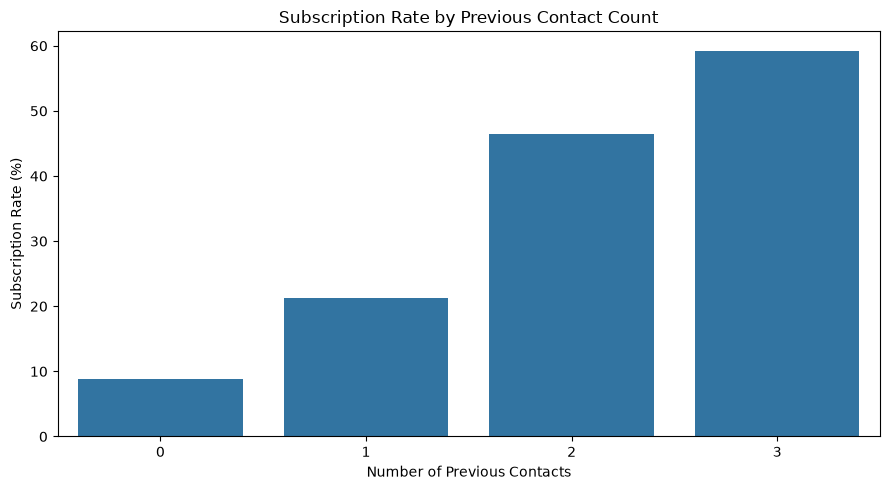

In [33]:
# Calculate subscription rates by previous contact count
previous_subscription = (
    df.groupby("previous")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

previous_sizes = df["previous"].value_counts()
common_previous_counts = previous_sizes[previous_sizes >= 100].index

previous_subscription_common = (
    previous_subscription.loc[common_previous_counts]
    .sort_index()
)

print("Subscription rate by previous contact count (%):")
print(previous_subscription_common.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=previous_subscription_common.index,
    y=previous_subscription_common.values
)

plt.title("Subscription Rate by Previous Contact Count")
plt.xlabel("Number of Previous Contacts")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

In [34]:
# Identify customers who were previously contacted
previously_contacted = (df["pdays"] != 999).sum()
not_previously_contacted = (df["pdays"] == 999).sum()

print("Previously contacted customers:", previously_contacted)
print("Customers with pdays = 999:", not_previously_contacted)

Previously contacted customers: 1515
Customers with pdays = 999: 39661


### Findings from Previous Contact History Analysis

The summary shows that most customers had no previous contacts recorded. A total of 35,551 customers had zero previous contacts, while 4,561 had one previous contact. Only a small number of customers had two or more previous contacts.

When I compared subscription rates, customers with three previous contacts had the highest rate among the displayed groups, at 59.26%. Customers with two previous contacts had a rate of 46.42%, while those with one previous contact had a rate of 21.20%. Customers with no previous contacts had a rate of 8.83%.

The `pdays` column also shows that 1,515 customers had been contacted previously, while 39,661 had a value of 999, indicating no previous contact recorded in the campaign history.

These results suggest that previous contact history may be useful when analysing subscription behaviour. However, the groups with multiple previous contacts are much smaller, so their high rates should be interpreted carefully. I will consider this information alongside other features when building the predictive model.

### Economic Indicators and Subscription Analysis

I will now explore the economic indicators included in the dataset. These variables describe the wider economic conditions during the marketing campaign.

I will first examine their distributions and summary statistics. Then, I will compare their values for customers who subscribed and those who did not. This may help me identify economic patterns associated with subscription behaviour.

In [35]:
# Summary statistics for economic indicators
economic_columns = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

df[economic_columns].describe().round(2)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.00,41176.00,41176.00,41176.00,41176.00
mean,0.08,93.58,-40.50,3.62,5167.03
std,1.57,0.58,4.63,1.73,72.25
min,-3.40,92.20,-50.80,0.63,4963.60
25%,-1.80,93.08,-42.70,1.34,5099.10
50%,1.10,93.75,-41.80,4.86,5191.00
75%,1.40,93.99,-36.40,4.96,5228.10
max,1.40,94.77,-26.90,5.04,5228.10


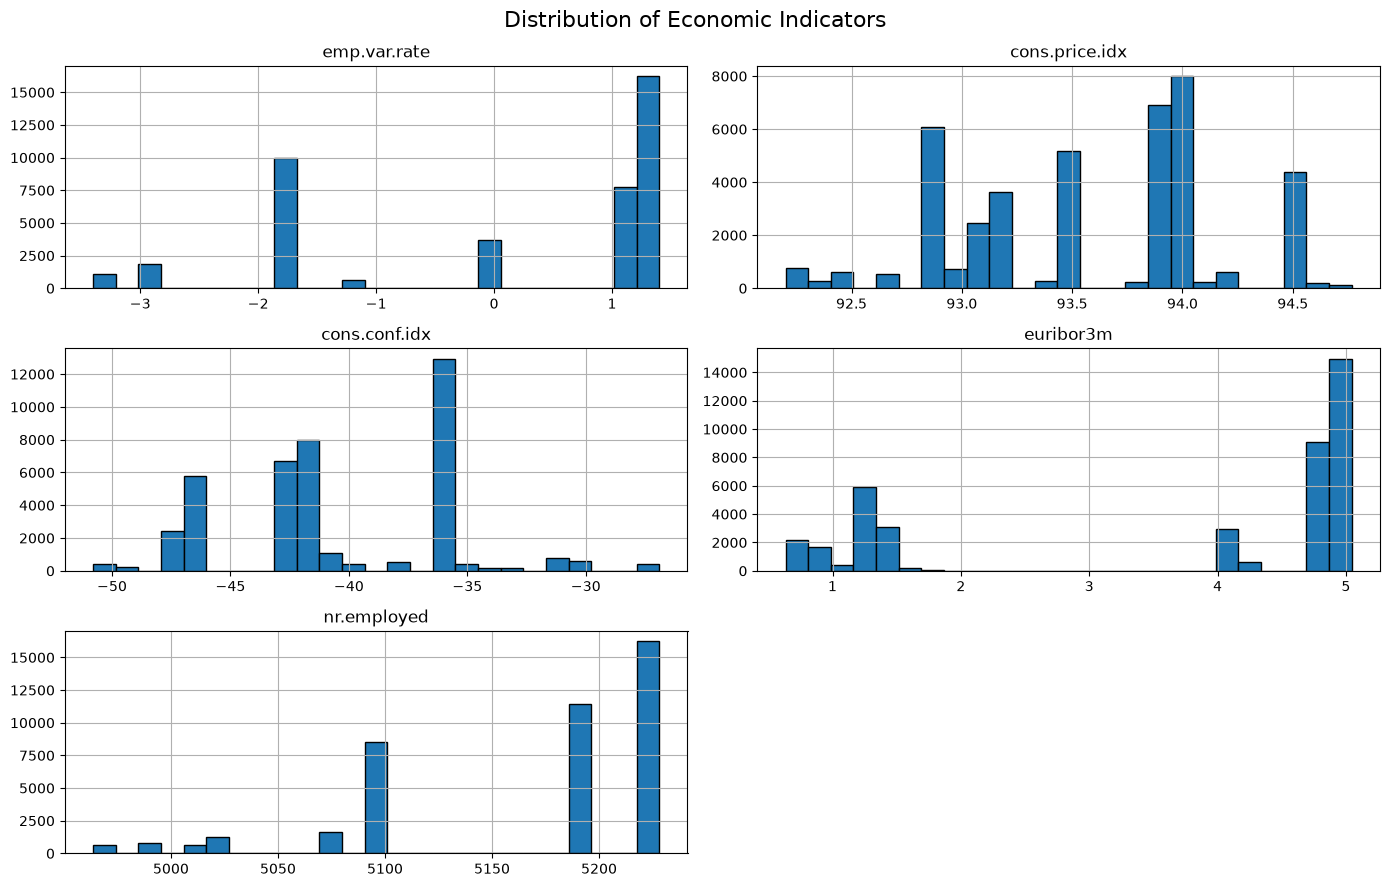

In [36]:
# Visualize the distributions of economic indicators
df[economic_columns].hist(
    bins=25,
    figsize=(14, 9),
    edgecolor="black"
)

plt.suptitle("Distribution of Economic Indicators", fontsize=16)
plt.tight_layout()
plt.show()

Average economic indicator values by subscription outcome:


y,no,yes
emp.var.rate,0.249,-1.233
cons.price.idx,93.604,93.355
cons.conf.idx,-40.593,-39.791
euribor3m,3.811,2.123
nr.employed,5176.166,5095.120


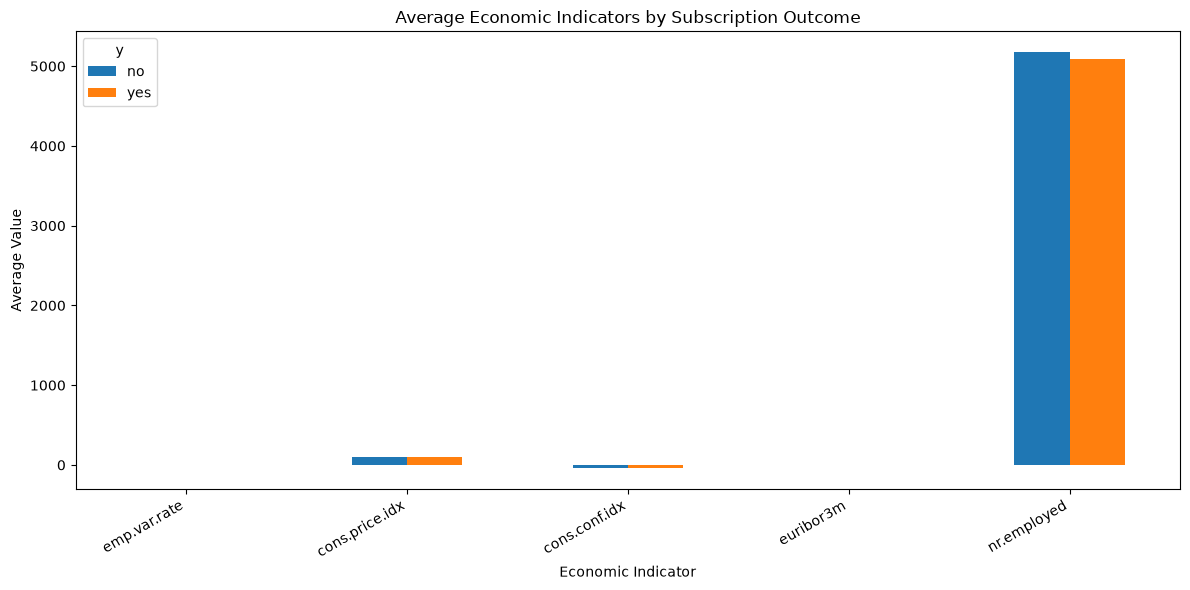

In [37]:
# Compare economic indicators for subscribed and non-subscribed customers
economic_comparison = df.groupby("y")[economic_columns].mean().T

print("Average economic indicator values by subscription outcome:")
display(economic_comparison.round(3))

economic_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Economic Indicators by Subscription Outcome")
plt.xlabel("Economic Indicator")
plt.ylabel("Average Value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Findings from Economic Indicator Analysis

The summary statistics show that the five economic indicators have different ranges and distributions. Some indicators are concentrated around particular values, which suggests that economic conditions were recorded at specific levels during the campaign period.

When I compared average values by subscription outcome, I found that customers who subscribed had a lower average employment variation rate (−1.233) than those who did not subscribe (0.249). Their average three-month Euribor rate was also lower, at 2.123 compared with 3.811, and their average number-of-employees indicator was 5,095.120 compared with 5,176.166.

The average consumer price index was slightly lower among customers who subscribed, while the average consumer confidence index was slightly higher.

These differences suggest that economic conditions may be associated with subscription behaviour. However, these are comparisons of averages, not proof that any one indicator caused customers to subscribe. I will consider these variables during model development and check how useful they are for prediction.

In [38]:
# Examine call duration
print("Call duration summary (seconds):")
print(df["duration"].describe().round(2))

# Compare average call duration by subscription outcome
duration_summary = (
    df.groupby("y")["duration"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("\nCall duration by subscription outcome:")
display(duration_summary)

Call duration summary (seconds):
count    41176.00
mean       258.32
std        259.31
min          0.00
25%        102.00
50%        180.00
75%        319.00
max       4918.00
Name: duration, dtype: float64

Call duration by subscription outcome:


,count,mean,median
y,,,
no,36537,220.87,164.0
yes,4639,553.26,449.0


### Call Duration and Information Leakage

I will examine call duration to understand how it differs between customers who subscribed and those who did not.

However, call duration is known only after a conversation has taken place. If the goal is to identify likely subscribers before making a call, this information would not be available at prediction time.

For this reason, I will exclude `duration` from the main pre-call prediction model. I will use the results of this analysis only to understand the dataset and explain why choosing the correct input features is important.

### Findings from Call Duration Analysis

The call duration summary shows that calls lasted an average of 258.32 seconds, with a median duration of 180 seconds. The longest recorded call lasted 4,918 seconds.

When I compared the two subscription groups, customers who subscribed had an average call duration of 553.26 seconds and a median of 449 seconds. For customers who did not subscribe, the average was 220.87 seconds and the median was 164 seconds.

This shows a clear difference in call duration between the two groups. However, longer calls do not necessarily cause customers to subscribe. Successful conversations may naturally continue for longer.

Since call duration is only available after a call has taken place, I will exclude this column from the main model, which is intended to help the marketing team identify potential subscribers before calling them.

### Overall Summary of Exploratory Data Analysis

Through this analysis, I explored customer demographics, previous campaign outcomes, contact methods, campaign timing, contact frequency and economic indicators.

The dataset contains 41,176 records after removing 12 exact duplicate rows. There are no standard missing values, although some categorical columns contain `unknown` values that need to be handled during preprocessing.

The target variable is imbalanced: 11.27% of customers subscribed to the term deposit, while 88.73% did not. I also observed differences in subscription rates across job categories, education levels, contact methods, campaign months and previous campaign outcomes.

These findings give me a better understanding of the dataset and help identify features worth testing during model development. The next stage is to prepare the data carefully, prevent information leakage and evaluate models using metrics that are appropriate for an imbalanced classification problem.

## 6. Data Preprocessing

After completing the exploratory analysis, I will prepare the dataset for machine learning. The aim is to organise the input features and target variable while making sure that the model only uses information that would be available at prediction time.

The target variable is `y`, which indicates whether a customer subscribed to the term deposit. I will exclude this column from the input features, along with `duration`, because call duration is only known after the conversation has taken place.

I will keep the original dataset unchanged and create separate variables for model preparation.

In [39]:
# Separate input features and target variable

X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget values:")
print(y.value_counts(normalize=True).mul(100).round(2))

Input features shape: (41176, 19)
Target variable shape: (41176,)

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64

Target values:
y
0    88.73
1    11.27
Name: proportion, dtype: float64


### Handling Unknown Categorical Values

During the data quality assessment, I found that some categorical columns contain values marked as `unknown`. These values indicate that the information was not available in the dataset.

Instead of deleting these records or replacing the values with guesses, I will keep `unknown` as a separate category. This allows the model to learn from the available information while preserving the original customer records.

I will encode the categorical features during preprocessing so that they can be used by machine learning algorithms.

In [40]:
# Count unknown values in categorical features

categorical_columns = X.select_dtypes(include="object").columns

unknown_counts = {}

for column in categorical_columns:
    count = (X[column] == "unknown").sum()
    if count > 0:
        unknown_counts[column] = count

print("Unknown values in input features:")

for column, count in unknown_counts.items():
    print(f"{column}: {count}")

print("\nTotal rows in X:", len(X))
print("Total missing values in X:", X.isnull().sum().sum())

Unknown values in input features:
job: 330
marital: 80
education: 1730
default: 8596
housing: 990
loan: 990

Total rows in X: 41176
Total missing values in X: 0


### Splitting the Data for Model Development

I will split the dataset into training and testing sets before encoding the categorical features or training any models. The training set will be used to fit the models, while the testing set will help me evaluate their performance on records they have not seen during training.

I will use an 80:20 split and stratify the data using the target variable. This will help preserve the proportion of customers who subscribed and did not subscribe in both sets.

I will also set a random state so that the split can be reproduced when I run the notebook again.

In [41]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features shape: (32940, 19)
Testing features shape: (8236, 19)

Training target distribution (%):
y
0    88.73
1    11.27
Name: proportion, dtype: float64

Testing target distribution (%):
y
0    88.73
1    11.27
Name: proportion, dtype: float64


### Preparing Numerical and Categorical Features

After splitting the dataset, I will prepare the features for machine learning. The dataset contains both numerical information, such as age and economic indicators, and categorical information, such as job, education and contact method.

I will use One-Hot Encoding to convert categorical values into numerical features. I will also standardise the numerical columns so that differences in their scales do not unnecessarily affect certain models.

To prevent data leakage, I will create a preprocessing pipeline that learns the required transformations from the training data only. The same transformations will later be applied to the testing data.

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical columns
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumerical features:", numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of categorical features: 10
Number of numerical features: 9


In [43]:
# Create preprocessing steps for each feature type
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")
print(preprocessor)

Preprocessing pipeline created successfully!
ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['job', 'marital', 'education', 'default',
                                  'housing', 'loan', 'contact', 'month',
                                  'day_of_week', 'poutcome']),
                                ('numerical', StandardScaler(),
                                 ['age', 'campaign', 'pdays', 'previous',
                                  'emp.var.rate', 'cons.price.idx',
                                  'cons.conf.idx', 'euribor3m',
                                  'nr.employed'])])


## 7. Machine Learning Model Building

After preparing the features, I will begin training machine learning models to predict whether a customer is likely to subscribe to a term deposit.

I will start with Logistic Regression because it provides a useful baseline for a binary classification problem. I will combine it with the preprocessing pipeline so that categorical encoding and numerical scaling are learned from the training data only.

Since relatively few customers subscribed, I will not judge the model using accuracy alone. I will also examine precision, recall, F1-score and ROC-AUC to get a clearer picture of its performance.

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train the model using training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict the test set
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Logistic Regression - Test Results")
print("-----------------------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Subscription", "Subscription"]
))

Logistic Regression - Test Results
-----------------------------------
Accuracy:  0.8983
Precision: 0.6500
Recall:    0.2101
F1-score:  0.3176
ROC-AUC:   0.8004

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.91      0.99      0.95      7308
   Subscription       0.65      0.21      0.32       928

       accuracy                           0.90      8236
      macro avg       0.78      0.60      0.63      8236
   weighted avg       0.88      0.90      0.87      8236



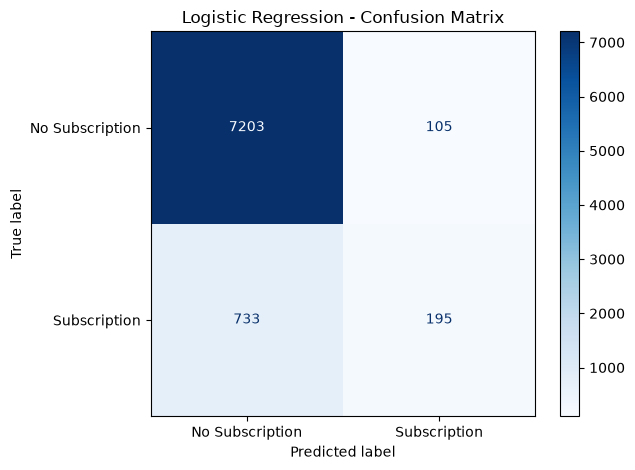

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Subscription", "Subscription"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

### Random Forest Model

After evaluating the baseline Logistic Regression model, I will try Random Forest to see whether a more flexible algorithm improves prediction performance.

Random Forest combines predictions from multiple decision trees. This allows it to learn more complex patterns in the customer and campaign data.

I will use the same training and testing sets and retain the preprocessing pipeline. This will make the results easier to compare fairly with the baseline model.

In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Create the Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Predict on unseen test data
rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Display evaluation metrics
print("Random Forest - Test Results")
print("-----------------------------")
print(f"Accuracy:  {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

Random Forest - Test Results
-----------------------------
Accuracy:  0.8940
Precision: 0.5562
Recall:    0.2931
F1-score:  0.3839
ROC-AUC:   0.7843

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.92      0.97      0.94      7308
   Subscription       0.56      0.29      0.38       928

       accuracy                           0.89      8236
      macro avg       0.74      0.63      0.66      8236
   weighted avg       0.87      0.89      0.88      8236



In [48]:
# Compare the two models on the same test set
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8983,0.6500,0.2101,0.3176,0.8004
1,Random Forest,0.8940,0.5562,0.2931,0.3839,0.7843


### Testing a Gradient Boosting Model

The first two models produced different results. Logistic Regression achieved higher accuracy and ROC-AUC, while Random Forest achieved higher recall and F1-score.

I will now test a gradient boosting model to see whether it can improve the balance between identifying subscribers and making accurate predictions. I will keep the same training and testing sets so that the results remain comparable.

In [49]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Use a dense One-Hot Encoder for HistGradientBoosting
gb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ],
    sparse_threshold=0
)

# Create the Gradient Boosting pipeline
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.1,
            random_state=42
        ))
    ]
)

# Train the model
gradient_boosting_model.fit(X_train, y_train)

# Predict on the test set
gb_pred = gradient_boosting_model.predict(X_test)
gb_prob = gradient_boosting_model.predict_proba(X_test)[:, 1]

# Display evaluation metrics
print("Gradient Boosting - Test Results")
print("--------------------------------")
print(f"Accuracy:  {accuracy_score(y_test, gb_pred):.4f}")
print(f"Precision: {precision_score(y_test, gb_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, gb_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, gb_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, gb_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    gb_pred,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

Gradient Boosting - Test Results
--------------------------------
Accuracy:  0.8996
Precision: 0.6391
Recall:    0.2500
F1-score:  0.3594
ROC-AUC:   0.8141

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.91      0.98      0.95      7308
   Subscription       0.64      0.25      0.36       928

       accuracy                           0.90      8236
      macro avg       0.78      0.62      0.65      8236
   weighted avg       0.88      0.90      0.88      8236



In [50]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0),
        precision_score(y_test, gb_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, gb_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, gb_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, gb_prob)
    ]
})

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8983,0.6500,0.2101,0.3176,0.8004
1,Random Forest,0.8940,0.5562,0.2931,0.3839,0.7843
2,Gradient Boosting,0.8996,0.6391,0.2500,0.3594,0.8141


### Testing XGBoost

The three models tested so far have achieved accuracy values close to 90%. Gradient Boosting produced the highest accuracy and ROC-AUC, while Random Forest performed better on recall and F1-score.

I will now test XGBoost to see whether it can improve the results. I will use the same training and testing sets and evaluate it with the same metrics so that the comparison remains fair.

The aim is to improve performance without using information that would not be available before a customer is contacted.

In [51]:
try:
    import xgboost
    print("XGBoost version:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost version: 3.4.1


### XGBoost Model Building and Evaluation

In this step, I am using XGBoost, a machine learning algorithm that combines multiple decision trees to identify patterns in the data. I will train the model using the training dataset and evaluate its performance on the test dataset.

I will compare its accuracy, precision, recall, F1-score, and ROC-AUC with the models tested earlier. Since most customers in this dataset did not subscribe to a term deposit, I will also pay attention to how well the model identifies customers who actually subscribed.

The `duration` column is excluded because call duration is only known after a phone call ends. Using it would make the model less realistic for predicting which customers to contact before a call.

In [52]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Build the XGBoost pipeline
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
xgb_model.fit(X_train, y_train)

# Make predictions
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("XGBoost Model Performance")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, xgb_pred):.4f}")
print(f"Precision: {precision_score(y_test, xgb_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, xgb_pred, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, xgb_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, xgb_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

XGBoost Model Performance
-----------------------------------
Accuracy:  0.8981
Precision: 0.6226
Recall:    0.2435
F1-Score:  0.3501
ROC-AUC:   0.8109

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.91      0.98      0.94      7308
   Subscription       0.62      0.24      0.35       928

       accuracy                           0.90      8236
      macro avg       0.77      0.61      0.65      8236
   weighted avg       0.88      0.90      0.88      8236



### XGBoost Hyperparameter Tuning

The initial XGBoost model achieved approximately 89.81% accuracy. However, its recall for customers who subscribed was only 24.35%. This indicates that the model missed many actual subscribers.

In this step, I will adjust the class weighting to account for the imbalance between subscribers and non-subscribers. I will compare the results using the same test set and evaluate whether the changes improve recall and F1-score without relying only on accuracy.

In [53]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Calculate class weight from the training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
class_weight = negative_count / positive_count

print("Positive-class weight:", round(class_weight, 2))

# Train XGBoost with class weighting
xgb_weighted_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=class_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_weighted_model.fit(X_train, y_train)

# Evaluate using the default classification threshold
weighted_pred = xgb_weighted_model.predict(X_test)
weighted_prob = xgb_weighted_model.predict_proba(X_test)[:, 1]

print("\nWeighted XGBoost Performance")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, weighted_pred):.4f}")
print(f"Precision: {precision_score(y_test, weighted_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, weighted_pred, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, weighted_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, weighted_prob):.4f}")

Positive-class weight: 7.88

Weighted XGBoost Performance
-----------------------------------
Accuracy:  0.8445
Precision: 0.3877
Recall:    0.6562
F1-Score:  0.4874
ROC-AUC:   0.8117


### Prediction Threshold Optimization

The weighted XGBoost model improved recall by assigning greater importance to the subscription class. However, its accuracy decreased. In this step, I will evaluate different prediction thresholds using the model's predicted probabilities.

This experiment will help me understand the trade-off between identifying more potential subscribers and avoiding unnecessary customer targeting. I will compare accuracy, precision, recall, and F1-score at each threshold before selecting a suitable operating point.

In [54]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get predicted probabilities from the weighted model
weighted_prob = xgb_weighted_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    threshold_pred = (weighted_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, threshold_pred),
        "Precision": precision_score(
            y_test, threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, threshold_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Accuracy  Precision  Recall  F1-Score
      0.30    0.5610     0.1827  0.8341    0.2998
      0.35    0.6869     0.2347  0.7866    0.3615
      0.40    0.7677     0.2894  0.7295    0.4144
      0.45    0.8192     0.3480  0.6918    0.4630
      0.50    0.8445     0.3877  0.6562    0.4874
      0.55    0.8632     0.4273  0.6304    0.5094
      0.60    0.8745     0.4575  0.6142    0.5244
      0.65    0.8814     0.4787  0.5927    0.5296
      0.70    0.8856     0.4934  0.5647    0.5266


### Analysis of Prediction Thresholds

I evaluated the weighted XGBoost model at different prediction thresholds. As the threshold increased, accuracy and precision generally improved, while recall decreased. The highest F1-score among the tested thresholds was 0.5296 at a threshold of 0.65.

This experiment demonstrates the trade-off between identifying potential subscribers and avoiding incorrect predictions. The final threshold should be selected according to the bank's marketing objectives and validated separately from the final test data.

### XGBoost Hyperparameter Tuning

In this step, I will experiment with different XGBoost hyperparameters, including the number of trees, tree depth, and learning rate. These settings influence how the model learns patterns from the training data.

I will use cross-validation on the training dataset to compare different configurations. This helps me select a suitable model without repeatedly tuning it against the test dataset. After selecting the best configuration, I will evaluate it on the test dataset and compare its performance with the previous models.

In [55]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Build the pipeline
xgb_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Try a small set of hyperparameter combinations
param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.03, 0.1],
    "classifier__subsample": [0.8],
    "classifier__colsample_bytree": [0.8]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

xgb_grid_search = GridSearchCV(
    estimator=xgb_tuning_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Train and compare configurations using training data only
xgb_grid_search.fit(X_train, y_train)

print("Best parameters:")
print(xgb_grid_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(round(xgb_grid_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'classifier__colsample_bytree': 0.8, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 5, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}

Best cross-validation ROC-AUC:
0.7993


In [56]:
best_xgb_model = xgb_grid_search.best_estimator_

best_xgb_pred = best_xgb_model.predict(X_test)
best_xgb_prob = best_xgb_model.predict_proba(X_test)[:, 1]

print("Tuned XGBoost Model Performance")
print("-" * 40)
print(f"Accuracy:  {accuracy_score(y_test, best_xgb_pred):.4f}")
print(f"Precision: {precision_score(y_test, best_xgb_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, best_xgb_pred, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, best_xgb_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, best_xgb_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_xgb_pred,
    target_names=["No Subscription", "Subscription"],
    zero_division=0
))

Tuned XGBoost Model Performance
----------------------------------------
Accuracy:  0.9000
Precision: 0.6486
Recall:    0.2446
F1-Score:  0.3552
ROC-AUC:   0.8153

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.91      0.98      0.95      7308
   Subscription       0.65      0.24      0.36       928

       accuracy                           0.90      8236
      macro avg       0.78      0.61      0.65      8236
   weighted avg       0.88      0.90      0.88      8236



### Comparative Evaluation of Machine Learning Models

In this step, I will compare the performance of Logistic Regression, Random Forest, Gradient Boosting, the original XGBoost model, and tuned XGBoost. I will compare accuracy, precision, recall, F1-score, and ROC-AUC to understand the strengths and limitations of each model.

This comparison will help identify the most promising model for predicting term deposit subscriptions. I will consider the bank's goal of identifying potential subscribers rather than selecting a model based on accuracy alone.

In [57]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

model_results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, logistic_model.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_pred, zero_division=0),
        "F1-Score": f1_score(y_test, rf_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, random_forest_model.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Gradient Boosting",
        "Accuracy": accuracy_score(y_test, gb_pred),
        "Precision": precision_score(y_test, gb_pred, zero_division=0),
        "Recall": recall_score(y_test, gb_pred, zero_division=0),
        "F1-Score": f1_score(y_test, gb_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, gradient_boosting_model.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Original XGBoost",
        "Accuracy": accuracy_score(y_test, xgb_pred),
        "Precision": precision_score(y_test, xgb_pred, zero_division=0),
        "Recall": recall_score(y_test, xgb_pred, zero_division=0),
        "F1-Score": f1_score(y_test, xgb_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, xgb_prob)
    },
    {
        "Model": "Tuned XGBoost",
        "Accuracy": accuracy_score(y_test, best_xgb_pred),
        "Precision": precision_score(
            y_test, best_xgb_pred, zero_division=0
        ),
        "Recall": recall_score(y_test, best_xgb_pred, zero_division=0),
        "F1-Score": f1_score(y_test, best_xgb_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, best_xgb_prob)
    }
]

comparison_df = pd.DataFrame(model_results)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8983     0.6500  0.2101    0.3176   0.8004
      Random Forest    0.8940     0.5562  0.2931    0.3839   0.7843
  Gradient Boosting    0.8996     0.6391  0.2500    0.3594   0.8141
   Original XGBoost    0.8981     0.6226  0.2435    0.3501   0.8109
      Tuned XGBoost    0.9000     0.6486  0.2446    0.3552   0.8153


## Feature Importance Analysis Using Tuned XGBoost

After comparing five machine learning models, I selected tuned XGBoost as the primary candidate because it achieved the highest accuracy (90.00%) and ROC-AUC (81.53%) among the models tested.

In this step, I will analyse feature importance to identify which customer characteristics and campaign-related factors the model uses most when predicting term deposit subscriptions.

These findings can help the bank understand patterns in customer responses and develop more focused marketing strategies. Feature importance indicates predictive usefulness, not proof of cause and effect.

Top 15 Important Features:
                       Feature  Importance
        numerical__nr.employed    0.431742
 categorical__poutcome_success    0.076371
       numerical__emp.var.rate    0.042493
        categorical__month_oct    0.032863
      numerical__cons.conf.idx    0.028033
              numerical__pdays    0.027218
          numerical__euribor3m    0.019085
categorical__contact_telephone    0.017941
        categorical__month_may    0.016871
        categorical__month_apr    0.014990
 categorical__contact_cellular    0.012224
       categorical__default_no    0.011613
     numerical__cons.price.idx    0.011594
        categorical__month_mar    0.011357
 categorical__poutcome_failure    0.010522


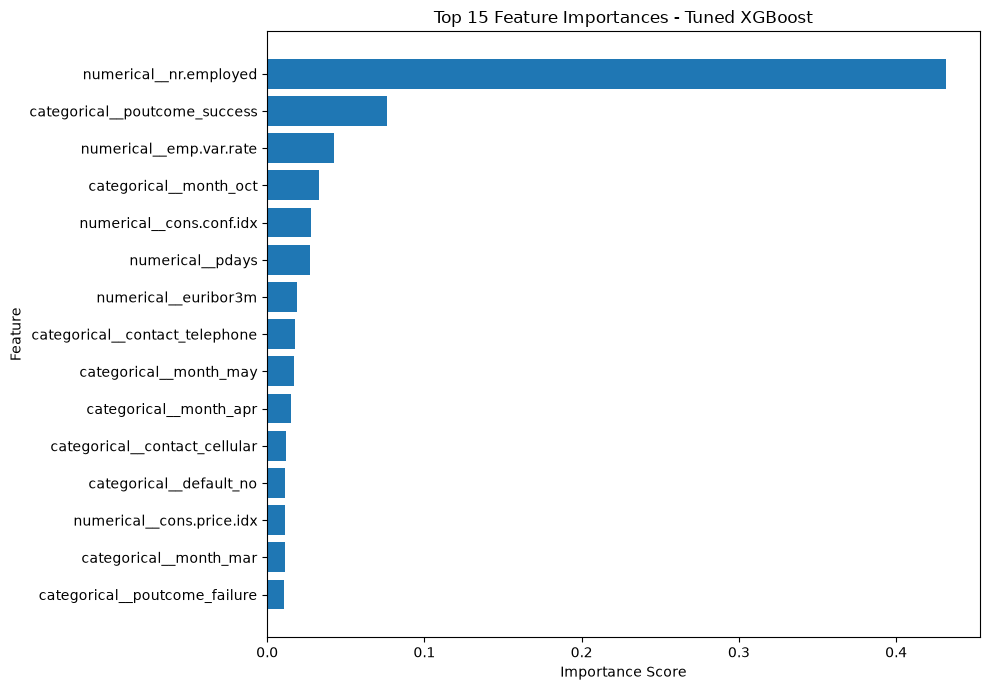

In [58]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the trained XGBoost classifier
xgb_classifier = best_xgb_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = (
    best_xgb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_classifier.feature_importances_
})

# Select the 15 most important features
top_features = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

print("Top 15 Important Features:")
print(top_features.to_string(index=False))

# Visualise feature importance
plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)
plt.title("Top 15 Feature Importances - Tuned XGBoost")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Interpretation of Feature Importance Results

The feature importance analysis identified `nr.employed` as the most influential feature in the tuned XGBoost model, with an importance score of approximately 0.4317. The previous campaign outcome `poutcome_success` ranked second, followed by `emp.var.rate` and the October month indicator.

The results suggest that economic indicators, previous campaign outcomes, and campaign timing contribute to the model's predictions. These findings can help the bank understand patterns associated with term deposit subscriptions and develop data-informed marketing strategies.

However, feature importance does not establish causation or show whether a feature has a positive or negative effect on subscription probability. Further analysis is needed before making specific targeting decisions.

## Business Insights and Marketing Recommendations

The analysis of the Portuguese Bank Marketing dataset revealed several patterns related to customer subscriptions. The results show that previous campaign outcomes, economic indicators, contact methods, and campaign timing are associated with subscription predictions.

Based on these findings, the bank can develop more focused marketing strategies, evaluate its campaign performance, and use customer information to prioritise future outreach. The recommendations below are suggestions based on observed associations and should be tested through controlled marketing experiments before being adopted at scale.

### Key Business Insights

**1. Previous campaign outcomes**

Customers with a successful previous campaign outcome had a much higher subscription rate than customers whose previous outcome was unsuccessful or nonexistent. The bank can evaluate whether these customers respond well to follow-up campaigns.

**2. Contact method**

The observed subscription rate was approximately 14.74% for cellular contacts and 5.23% for telephone contacts. The bank can investigate whether the difference remains after accounting for other customer and campaign characteristics.

**3. Campaign timing**

Subscription rates varied substantially across months. March, September, October, and December showed relatively high rates, although some months had fewer observations. The bank should validate these patterns using campaign volume and costs before reallocating resources.

**4. Economic indicators**

The model assigned high feature importance to `nr.employed` and `emp.var.rate`. Economic conditions may help explain variation in subscription outcomes, but these indicators should not be interpreted as direct causes of customer behaviour.

**5. Customer targeting**

The tuned XGBoost model achieved 90.00% accuracy and a ROC-AUC of 81.53% in the current test evaluation. However, its recall was 24.46% at the default threshold. The bank should consider the trade-off between reaching more potential subscribers and contacting customers who are unlikely to subscribe.

### Recommendations for the Bank

1. **Prioritise evidence-based follow-ups:** Evaluate follow-up campaigns for customers with successful previous campaign outcomes.

2. **Optimise contact channels:** Compare the effectiveness and cost of cellular and telephone campaigns using controlled tests.

3. **Test campaign timing:** Run small experiments across different months and periods to determine when campaigns perform best.

4. **Use predictive scores carefully:** Use model probabilities to help prioritise outreach, while selecting a decision threshold based on campaign costs and business objectives.

5. **Monitor model performance:** Track precision, recall, F1-score, ROC-AUC, and campaign conversion rates as new campaign results become available.

6. **Validate before deployment:** Test recommendations on new or later-period data before applying them to real marketing campaigns. Avoid treating feature importance or historical associations as proof of causation.

In [64]:
print("best_xgb_model" in globals())

True


In [65]:
import joblib

joblib.dump(
    best_xgb_model,
    "xgboost_bank_marketing.pkl"
)

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


## Interactive Bank Marketing Prediction Interface

This interface allows users to enter customer details and obtain a prediction from the trained XGBoost model. It displays the predicted subscription outcome and estimated probability, making the machine learning model easier to demonstrate and use.

In [71]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# Load the saved model
import joblib
model = joblib.load("xgboost_bank_marketing.pkl")

# Input fields
age = widgets.IntSlider(
    value=35, min=17, max=98, description="Age:"
)

job = widgets.Dropdown(
    options=[
        "admin.", "blue-collar", "entrepreneur", "housemaid",
        "management", "retired", "self-employed", "services",
        "student", "technician", "unemployed", "unknown"
    ],
    value="admin.", description="Job:"
)

marital = widgets.Dropdown(
    options=["married", "single", "divorced", "unknown"],
    value="single", description="Marital:"
)

education = widgets.Dropdown(
    options=[
        "university.degree", "high.school", "basic.4y",
        "basic.6y", "basic.9y", "professional.course",
        "illiterate", "unknown"
    ],
    value="university.degree", description="Education:"
)

default = widgets.Dropdown(
    options=["no", "yes", "unknown"], value="no",
    description="Default:"
)

housing = widgets.Dropdown(
    options=["no", "yes", "unknown"], value="no",
    description="Housing:"
)

loan = widgets.Dropdown(
    options=["no", "yes", "unknown"], value="no",
    description="Personal loan:"
)

contact = widgets.Dropdown(
    options=["cellular", "telephone"], value="cellular",
    description="Contact:"
)

month = widgets.Dropdown(
    options=["mar", "apr", "may", "jun", "jul",
             "aug", "sep", "oct", "nov", "dec"],
    value="oct", description="Month:"
)

day_of_week = widgets.Dropdown(
    options=["mon", "tue", "wed", "thu", "fri"],
    value="mon", description="Weekday:"
)

campaign = widgets.IntSlider(
    value=1, min=1, max=56, description="Campaign:"
)

pdays = widgets.IntSlider(
    value=999, min=0, max=999, description="Pdays:"
)

previous = widgets.IntSlider(
    value=0, min=0, max=7, description="Previous:"
)

poutcome = widgets.Dropdown(
    options=["nonexistent", "failure", "success"],
    value="nonexistent", description="Prev. outcome:"
)

emp_var_rate = widgets.FloatText(
    value=0.0, description="Emp. var. rate:"
)

cons_price_idx = widgets.FloatText(
    value=93.5, description="Price index:"
)

cons_conf_idx = widgets.FloatText(
    value=-40.0, description="Confidence:"
)

euribor3m = widgets.FloatText(
    value=3.5, description="Euribor 3m:"
)

nr_employed = widgets.FloatText(
    value=5100.0, description="Nr. employed:"
)

predict_button = widgets.Button(
    description="Predict Subscription",
    button_style="primary",
    icon="check"
)

output = widgets.Output()

def predict_subscription(button):
    with output:
        clear_output(wait=True)

        customer = pd.DataFrame([{
            "age": age.value,
            "job": job.value,
            "marital": marital.value,
            "education": education.value,
            "default": default.value,
            "housing": housing.value,
            "loan": loan.value,
            "contact": contact.value,
            "month": month.value,
            "day_of_week": day_of_week.value,
            "campaign": campaign.value,
            "pdays": pdays.value,
            "previous": previous.value,
            "poutcome": poutcome.value,
            "emp.var.rate": emp_var_rate.value,
            "cons.price.idx": cons_price_idx.value,
            "cons.conf.idx": cons_conf_idx.value,
            "euribor3m": euribor3m.value,
            "nr.employed": nr_employed.value
        }])

        try:
            probability = model.predict_proba(customer)[0, 1]
            prediction = model.predict(customer)[0]

            print("BANK MARKETING PREDICTION")
            print("=" * 32)
            print(f"Subscription probability: {probability:.2%}")
            print(
                "Predicted outcome:",
                "YES - Likely to subscribe"
                if int(prediction) == 1
                else "NO - Unlikely to subscribe"
            )
            print("\nThis is a model estimate, not a guarantee.")

        except Exception as error:
            print("Prediction error:", error)

predict_button.on_click(predict_subscription)

form = widgets.VBox([
    widgets.HTML("<h2>Bank Marketing AI</h2>"),
    widgets.HTML("<p>Enter customer details to predict subscription.</p>"),
    widgets.HBox([age, job]),
    widgets.HBox([marital, education]),
    widgets.HBox([default, housing]),
    widgets.HBox([loan, contact]),
    widgets.HBox([month, day_of_week]),
    widgets.HBox([campaign, pdays]),
    widgets.HBox([previous, poutcome]),
    widgets.HBox([emp_var_rate, cons_price_idx]),
    widgets.HBox([cons_conf_idx, euribor3m]),
    nr_employed,
    predict_button,
    output
])

display(form)

In [67]:
# Find real customer profiles with high predicted probabilities

import pandas as pd

# Load the dataset and remove duplicate records
customer_data = pd.read_csv(
    "Data/bank-additional/bank-additional-full.csv",
    sep=";"
).drop_duplicates().reset_index(drop=True)

# Use only information available before the call
X_customers = customer_data.drop(columns=["y", "duration"])

# Predict subscription probabilities
customer_data["predicted_probability"] = (
    model.predict_proba(X_customers)[:, 1]
)

# Display the 15 customers with the highest predicted probabilities
top_customers = customer_data.sort_values(
    "predicted_probability",
    ascending=False
).head(15)

display(
    top_customers[
        [
            "age", "job", "marital", "education", "contact",
            "month", "campaign", "poutcome",
            "predicted_probability", "y"
        ]
    ].style.format({
        "predicted_probability": "{:.2%}"
    })
)

,age,job,marital,education,contact,month,campaign,poutcome,predicted_probability,y
39636,60,admin.,married,unknown,cellular,may,1,success,91.40%,yes
39526,52,admin.,married,unknown,telephone,apr,1,success,90.89%,yes
39628,66,blue-collar,married,unknown,cellular,may,2,success,90.05%,yes
40458,75,retired,married,basic.4y,cellular,aug,2,success,89.28%,yes
40843,41,admin.,married,unknown,cellular,sep,1,success,89.27%,yes
40457,92,retired,married,unknown,cellular,aug,1,success,89.26%,yes
40438,92,retired,married,unknown,cellular,aug,1,success,89.09%,yes
39466,75,retired,divorced,high.school,telephone,apr,1,success,88.90%,yes
40409,77,management,married,unknown,cellular,aug,1,success,88.53%,yes
40461,66,admin.,divorced,university.degree,cellular,aug,3,success,88.29%,yes


In [68]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predict probabilities for unseen test customers
test_probabilities = best_xgb_model.predict_proba(X_test)[:, 1]

# Use the default 0.50 threshold
test_predictions = (test_probabilities >= 0.50).astype(int)

print("TEST SET EVALUATION")
print("-" * 35)
print(f"Customers tested: {len(y_test)}")
print(f"Predicted subscribers: {test_predictions.sum()}")
print(f"Actual subscribers: {int(y_test.sum())}")
print(f"Precision: {precision_score(y_test, test_predictions):.2%}")
print(f"Recall: {recall_score(y_test, test_predictions):.2%}")
print(f"F1-score: {f1_score(y_test, test_predictions):.2%}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

TEST SET EVALUATION
-----------------------------------
Customers tested: 8236
Predicted subscribers: 350
Actual subscribers: 928
Precision: 64.86%
Recall: 24.46%
F1-score: 35.52%

Confusion Matrix:
[[7185  123]
 [ 701  227]]


In [69]:
# Find a real historical customer with a successful subscription
sample_customers = customer_data[
    (customer_data["y"] == "yes") &
    (customer_data["poutcome"] == "success")
].copy()

# Show the five highest-scoring examples
display(
    sample_customers.nlargest(5, "predicted_probability")[
        [
            "age", "job", "contact", "month",
            "pdays", "previous", "poutcome",
            "predicted_probability", "y"
        ]
    ].style.format({
        "predicted_probability": "{:.2%}"
    })
)

,age,job,contact,month,pdays,previous,poutcome,predicted_probability,y
39636,60,admin.,cellular,may,6,2,success,91.40%,yes
39526,52,admin.,telephone,apr,6,1,success,90.89%,yes
39628,66,blue-collar,cellular,may,6,2,success,90.05%,yes
40458,75,retired,cellular,aug,6,3,success,89.28%,yes
40843,41,admin.,cellular,sep,7,3,success,89.27%,yes


In [72]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# Load the original dataset
customer_data = pd.read_csv(
    "Data/bank-additional/bank-additional-full.csv",
    sep=";"
).drop_duplicates().reset_index(drop=True)

# Prepare customer features
X_customers = customer_data.drop(columns=["y", "duration"])

# Score customers using the saved model
customer_data["predicted_probability"] = (
    model.predict_proba(X_customers)[:, 1]
)

# Keep high-scoring examples for demonstration
top_customers = customer_data.nlargest(
    100, "predicted_probability"
)

customer_options = [
    (
        f"Age {row.age} | {row.job} | {row.month} | "
        f"Probability {row.predicted_probability:.1%}",
        idx
    )
    for idx, row in top_customers.iterrows()
]

customer_selector = widgets.Dropdown(
    options=customer_options,
    description="Sample:",
    layout=widgets.Layout(width="650px")
)

predict_sample_button = widgets.Button(
    description="Predict Selected Customer",
    button_style="primary"
)

sample_output = widgets.Output()

def predict_selected_customer(button):
    with sample_output:
        clear_output(wait=True)

        idx = customer_selector.value
        row = customer_data.loc[idx]
        customer = X_customers.loc[[idx]]

        probability = model.predict_proba(customer)[0, 1]
        prediction = model.predict(customer)[0]

        print("CUSTOMER PREDICTION")
        print("-" * 35)
        print(f"Age: {row['age']}")
        print(f"Job: {row['job']}")
        print(f"Contact: {row['contact']}")
        print(f"Month: {row['month']}")
        print(f"Previous outcome: {row['poutcome']}")
        print(f"Subscription probability: {probability:.2%}")
        print(
            "Predicted outcome:",
            "YES - Likely to subscribe"
            if int(prediction) == 1
            else "NO - Unlikely to subscribe"
        )
        print(f"Historical outcome: {row['y']}")
        print("\nHistorical outcome is not a guarantee of future results.")

predict_sample_button.on_click(predict_selected_customer)

display(
    widgets.VBox([
        widgets.HTML("<h3>Bank Marketing — Sample Customer Explorer</h3>"),
        customer_selector,
        predict_sample_button,
        sample_output
    ])
)

## Marketing Analytics Dashboard

This dashboard presents an overview of customer subscription outcomes and campaign performance using the Portuguese Bank Marketing dataset. It includes customer statistics, subscription distribution, and comparisons across contact methods and campaign months.

The purpose is to identify patterns in historical marketing data and support further investigation into campaign effectiveness.

BANK MARKETING ANALYTICS
Total customers: 41,176
Subscribed: 4,639
Not subscribed: 36,537
Overall subscription rate: 11.27%


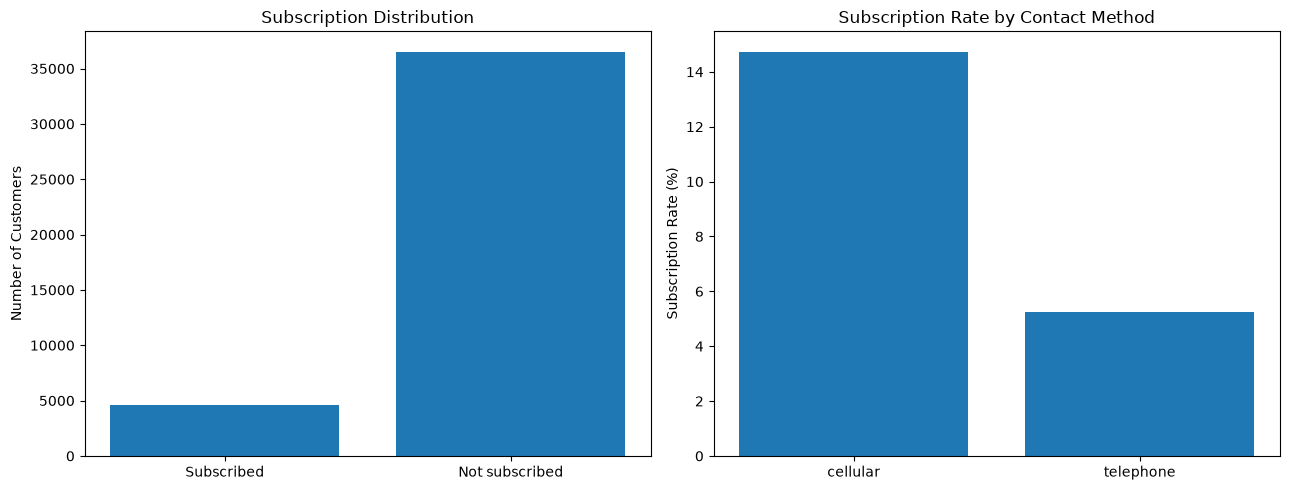

In [73]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the cleaned dataset
dashboard_df = pd.read_csv(
    "Data/bank-additional/bank-additional-full.csv",
    sep=";"
).drop_duplicates()

total = len(dashboard_df)
subscribed = (dashboard_df["y"] == "yes").sum()
not_subscribed = (dashboard_df["y"] == "no").sum()
rate = subscribed / total * 100

print("BANK MARKETING ANALYTICS")
print("=" * 40)
print(f"Total customers: {total:,}")
print(f"Subscribed: {subscribed:,}")
print(f"Not subscribed: {not_subscribed:,}")
print(f"Overall subscription rate: {rate:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subscription distribution
axes[0].bar(
    ["Subscribed", "Not subscribed"],
    [subscribed, not_subscribed]
)
axes[0].set_title("Subscription Distribution")
axes[0].set_ylabel("Number of Customers")

# Subscription rate by contact method
contact_rate = (
    dashboard_df.groupby("contact")["y"]
    .apply(lambda s: (s == "yes").mean() * 100)
)
axes[1].bar(contact_rate.index, contact_rate.values)
axes[1].set_title("Subscription Rate by Contact Method")
axes[1].set_ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

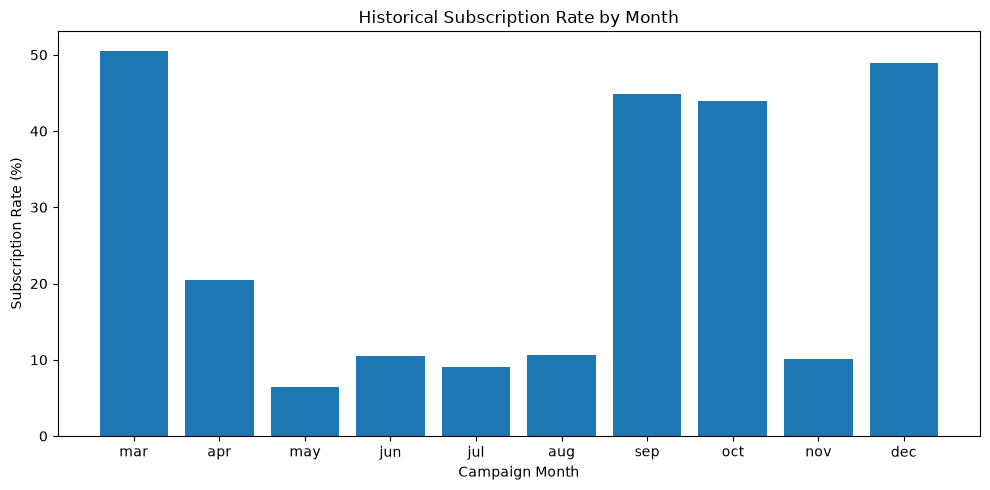

Monthly Subscription Rates:


,Subscription Rate (%)
month,
mar,50.55
apr,20.49
may,6.44
jun,10.51
jul,9.04
aug,10.61
sep,44.91
oct,43.93
nov,10.15


In [74]:
# Monthly subscription analysis

month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

monthly_analysis = (
    dashboard_df.groupby("month")["y"]
    .apply(lambda s: (s == "yes").mean() * 100)
    .reindex(month_order)
    .dropna()
)

plt.figure(figsize=(10, 5))
plt.bar(monthly_analysis.index, monthly_analysis.values)

plt.title("Historical Subscription Rate by Month")
plt.xlabel("Campaign Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Monthly Subscription Rates:")
display(
    monthly_analysis.rename("Subscription Rate (%)")
    .round(2)
    .to_frame()
)

## Key Insights from Marketing Analytics

1. **Overall subscription rate:** Approximately 11.27% of customers in the cleaned dataset subscribed to a term deposit, showing that the target classes are imbalanced.

2. **Contact method:** Cellular contacts had a historical subscription rate of approximately 14.74%, compared with 5.23% for telephone contacts. The bank should investigate whether this difference remains after accounting for other factors.

3. **Campaign month:** March, December, September, and October showed relatively high historical subscription rates. These patterns should be checked against campaign volumes and customer characteristics before changing campaign schedules.

4. **Model limitations:** The tuned XGBoost model achieved 90.00% accuracy and 81.53% ROC-AUC in the current evaluation. Its recall at the default threshold was 24.46%, meaning many actual subscribers were missed.

5. **Recommended action:** Use the model as a decision-support tool, validate it on later-period data, and test marketing strategies before implementing them at scale.

## Challenges Faced and Techniques Used

During this project, I encountered several challenges while preparing the Portuguese Bank Marketing dataset and developing the predictive models.

### 1. Duplicate Records

**Challenge:** The original dataset contained duplicate rows that could affect the analysis and model evaluation.

**Technique used:** I identified exact duplicate records and removed the extra copies using Pandas `drop_duplicates()`. This helped prevent repeated observations from unnecessarily influencing the analysis.

### 2. Unknown Categorical Values

**Challenge:** Some categorical columns contained the value `unknown`. These values represented unavailable or unspecified information rather than standard missing values.

**Technique used:** I retained `unknown` as a categorical value instead of automatically deleting those records or replacing the values without evidence. This preserved the available customer information.

### 3. Different Feature Types

**Challenge:** The dataset contained both numerical and categorical variables, which require different preprocessing techniques.

**Technique used:** I used `OneHotEncoder` for categorical features and `StandardScaler` for numerical features through a `ColumnTransformer` and machine learning pipeline.

### 4. Imbalanced Target Variable

**Challenge:** Approximately 88.73% of customers did not subscribe, while 11.27% subscribed. This imbalance made accuracy alone insufficient for evaluating the models.

**Technique used:** I compared precision, recall, F1-score, and ROC-AUC in addition to accuracy. I also tested class weighting and different prediction thresholds to understand the trade-off between identifying subscribers and producing false-positive predictions.

### 5. Avoiding Data Leakage

**Challenge:** The `duration` feature is strongly associated with the subscription outcome, but call duration is not known before a marketing call takes place.

**Technique used:** I excluded `duration` from the realistic predictive model so that the model uses information available before the call.

### 6. Model Selection and Performance

**Challenge:** The models achieved similar accuracy values, but their ability to identify actual subscribers differed.

**Technique used:** I compared Logistic Regression, Random Forest, Gradient Boosting, original XGBoost, and tuned XGBoost using the same train-test split. I considered multiple evaluation metrics rather than selecting a model based on accuracy alone.

### 7. Interactive Prediction Interface

**Challenge:** A trained model is not easy for a user to demonstrate without entering customer details through code.

**Technique used:** I developed an interactive form and a sample customer explorer using `ipywidgets`, allowing users to enter customer information and view predicted subscription probabilities directly in Jupyter Notebook.

### Learning Outcome

These challenges helped me understand the importance of data cleaning, suitable preprocessing, leakage prevention, imbalanced classification, model evaluation, and presenting machine learning predictions through an interactive interface.

# Conclusion

This project analysed the Portuguese Bank Marketing dataset to understand customer subscription behaviour and develop a machine learning model that can support term-deposit marketing campaigns.

The dataset was cleaned by removing duplicate records, and exploratory data analysis was performed to study customer characteristics, contact methods, campaign months, previous campaign outcomes, and economic indicators. The analysis showed that approximately 11.27% of customers subscribed to a term deposit, highlighting the need to evaluate models using multiple performance metrics.

Five machine learning approaches were compared: Logistic Regression, Random Forest, Gradient Boosting, original XGBoost, and tuned XGBoost. Among these models, the tuned XGBoost model achieved **90.00% accuracy** and a **ROC-AUC score of 81.53%** on the current test set. However, its recall for the subscription class was 24.46% at the default prediction threshold, meaning that many actual subscribers were not identified.

An interactive prediction interface and sample customer explorer were also developed in Jupyter Notebook. These components allow users to enter customer details, view predicted subscription probabilities, and explore historical customer examples. The analytics dashboard presents subscription statistics and historical patterns by contact method and month.

Based on the findings, the bank should use model predictions as decision-support information rather than guaranteed outcomes. It should evaluate the trade-off between identifying potential subscribers and contacting customers who may not subscribe. Further validation using later-period data and controlled marketing experiments is recommended before using the model in actual campaigns.

Overall, this project demonstrates the application of data cleaning, exploratory data analysis, preprocessing, machine learning, model evaluation, interactive visualisation, and business insight generation to a banking marketing problem.

# Model Comparison Report

## 1. Objective

The objective of this comparison was to evaluate different machine learning models and identify a suitable model for predicting whether a customer is likely to subscribe to a bank term deposit.

Five models were evaluated using the same test dataset: Logistic Regression, Random Forest, Gradient Boosting, XGBoost, and Tuned XGBoost.

## 2. Performance Comparison

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 89.83% | 65.00% | 21.01% | 31.76% | 80.04% |
| Random Forest | 89.40% | 55.62% | 29.31% | 38.39% | 78.43% |
| Gradient Boosting | 89.96% | 63.91% | 25.00% | 35.94% | 81.41% |
| XGBoost | 89.81% | 62.26% | 24.35% | 35.01% | 81.09% |
| Tuned XGBoost | 90.00% | 64.86% | 24.46% | 35.52% | 81.53% |

## 3. Comparison and Findings

- **Logistic Regression:** Provides a useful baseline and has relatively high precision, but its recall is low.
- **Random Forest:** Achieves the highest recall and F1-score among these five models, making it worth considering when identifying more potential subscribers is important.
- **Gradient Boosting:** Performs well in accuracy and ROC-AUC, showing good ability to distinguish between customers who subscribe and those who do not.
- **XGBoost:** Provides competitive performance and captures relationships between customer characteristics and subscription behaviour.
- **Tuned XGBoost:** Achieves the highest accuracy and ROC-AUC among the five evaluated models on the current test set.

## 4. Recommended Model

Tuned XGBoost is the recommended candidate for further evaluation because it achieved **90.00% accuracy** and a **ROC-AUC score of 81.53%**.

However, the model's recall is only **24.46%** at the default prediction threshold. This means it identifies only a portion of the customers who actually subscribed. Therefore, accuracy alone should not determine the final model choice.

If the bank's priority is to identify more potential subscribers, it should evaluate alternative probability thresholds and compare the associated precision, recall, F1-score, and campaign costs. Random Forest is also worth considering because it achieved a higher recall and F1-score at the default threshold.

## 5. Final Recommendation

The tuned XGBoost model should be treated as a candidate for further validation, rather than immediately deployed in a live marketing campaign. Before deployment, the bank should evaluate it on later-period data, select a decision threshold based on business objectives, and conduct controlled marketing experiments to measure its practical effectiveness.